# Fase 2 — Inferencia Estadística

**Grupo 10 — Ciencia de Datos**

Este notebook continúa el trabajo de `fase1_dataset_final.ipynb` (preparación de datos + análisis exploratorio) y desarrolla la **Fase 2 de la metodología (Inferencia estadística)**: formulación de hipótesis, ejecución de pruebas, verificación de supuestos y conclusiones.

**Hipótesis cubiertas en este notebook:** H1, H2, H3, H4 y H5 (las 5 planteadas al cierre de la Fase 1).

| Sección | Contenido |
|---|---|
| 1 | H2 — temperatura vs. ventas totales (regresión múltiple) |
| 2 | H1 — sección más sensible al clima (ANOVA de dos factores) |
| 3 | Preparación común para H3, H4 y H5 |
| 4 | H3 — el efecto del clima difiere entre secciones |
| 5 | H4 — el fin de semana modera el efecto climático |
| 6 | **H5 — el efecto climático varía por local** (incluye el **IC bootstrap** comparado con el clásico) |
| 7 | Variable de confusión |
| 8 | Comparaciones múltiples: cuándo se aplican y cuándo no |
| 9 | Tabla resumen H1–H5 (se genera desde las variables calculadas) |
| 10 | Conclusión general, limitaciones y variables para la Fase 3 |
| 11 | Auditoría de los requisitos de la Fase 2 |

**Corrección a la Fase 1 (se mantiene):** las ventas cubren únicamente **enero–septiembre de 2021 (271 fechas únicas)**, no tres años. El archivo meteorológico tiene 660 registros (20 estaciones × 33 meses, enero 2019 – septiembre 2021). El *merge* ventas–clima no perdió filas (9.447.662 antes y después).


# 0. Preparación del entorno

In [1]:
# Librerías de manipulación de datos
import pandas as pd
import numpy as np

# Librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías estadísticas
from scipy import stats
from scipy.stats import levene, f_oneway, kruskal
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [2]:
# Montaje de Google Drive (solo aplica en Google Colab; fuera de Colab se omite sin error)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("No se está ejecutando en Google Colab: se omite el montaje de Drive.")


No se está ejecutando en Google Colab: se omite el montaje de Drive.


In [3]:
# Ruta del dataset final. AJUSTAR según cómo tengas montada la carpeta compartida
# (puede ser 'grupo10_data_science/datos/df_final.parquet' o
#  'Colab Notebooks/grupo10_data_science/datos/df_final.parquet' según el acceso directo).
import os

RUTA_DF_FINAL = "/content/drive/MyDrive/grupo10_data_science/datos/df_final.parquet"

# Si no se está en Colab, se busca el archivo en la carpeta de trabajo (no cambia la ruta oficial de arriba).
rutas_candidatas = [RUTA_DF_FINAL, 'df_final.parquet', 'datos/df_final.parquet']
ruta_usada = next((r for r in rutas_candidatas if os.path.exists(r)), None)
if ruta_usada is None:
    raise FileNotFoundError(f"No se encontró df_final.parquet. Rutas probadas: {rutas_candidatas}")

# Se cargan solo las columnas que usa la Fase 2 (reduce la memoria; el resto del archivo no interviene en las pruebas).
COLUMNAS_FASE2 = ['fecha_vta', 'local', 'desc_secciones', 'desc_sub_secciones', 'cantidad',
                  'estacion_asignada', 'temperatura', 'es_fin_de_semana', 'es_feriado', 'mes']
df_final = pd.read_parquet(ruta_usada, columns=COLUMNAS_FASE2)

# Las columnas de texto con pocos valores distintos se pasan a 'category': mismo contenido, mucha menos memoria
# (con 9.4 millones de filas evita agotar la RAM de Colab al agregar datos más adelante).
for c_ in ['local', 'desc_secciones', 'desc_sub_secciones', 'estacion_asignada']:
    df_final[c_] = df_final[c_].astype('category')

print(f"Archivo: {ruta_usada}")
print(f"Dimensiones: {df_final.shape[0]:,} filas x {df_final.shape[1]} columnas (solo las usadas en la Fase 2)")
print(f"Fechas únicas de venta: {df_final['fecha_vta'].nunique()} "
      f"({df_final['fecha_vta'].min().date()} a {df_final['fecha_vta'].max().date()})")
df_final.head()


Archivo: df_final.parquet
Dimensiones: 9,447,662 filas x 10 columnas (solo las usadas en la Fase 2)
Fechas únicas de venta: 271 (2021-01-02 a 2021-09-30)


,fecha_vta,local,desc_secciones,desc_sub_secciones,cantidad,estacion_asignada,temperatura,es_fin_de_semana,es_feriado,mes
0,2021-01-02,Local X,Perecederos,Pastas Frescas,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...",27.3,True,False,1
1,2021-01-02,Local X,Perecederos,Pastas Frescas,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...",27.3,True,False,1
2,2021-01-02,Local X,Perecederos,Pastas Frescas,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...",27.3,True,False,1
3,2021-01-02,Local X,Perecederos,Lacteos,4.0,"Asunción, Silvio Pettirossi, Capital de la Rep...",27.3,True,False,1
4,2021-01-02,Local X,Perecederos,Lacteos,4.0,"Asunción, Silvio Pettirossi, Capital de la Rep...",27.3,True,False,1


# 1. H2 — Temperatura vs. ventas, controlando por calendario

**H0 (nula):** el coeficiente de `temperatura_promedio` en el modelo es igual a 0 (no hay asociación entre temperatura y ventas totales diarias, controlando por fin de semana, feriado y mes).

**H1 (alternativa):** el coeficiente de `temperatura_promedio` es distinto de 0 (sí hay asociación, en algún sentido, una vez controlado el calendario).

**Nivel de significancia:** α = 0.05

In [4]:
# --- 1.1 Agregación diaria ---
agg = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean'),
    mes=('mes', 'first'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
).reset_index()

agg['es_fin_de_semana'] = agg['es_fin_de_semana'].astype(int)
agg['es_feriado'] = agg['es_feriado'].astype(int)
agg['mes'] = agg['mes'].astype('category')

print(f"Observaciones (días): {len(agg)}")
agg.head()

Observaciones (días): 271


,fecha_vta,cantidad_total,temperatura_promedio,mes,es_fin_de_semana,es_feriado
0,2021-01-02,49828.3137,26.861887,1,1,0
1,2021-01-03,47241.1441,28.200439,1,1,0
2,2021-01-04,55018.2621,27.272368,1,0,0
3,2021-01-05,49574.9965,24.487014,1,0,0
4,2021-01-06,37930.7416,26.547221,1,0,0


In [5]:
# --- 1.2 Modelo de regresión múltiple (OLS) ---
modelo_h2 = smf.ols(
    'cantidad_total ~ temperatura_promedio + es_fin_de_semana + es_feriado + C(mes)',
    data=agg
).fit()

print(modelo_h2.summary())

                            OLS Regression Results                            
Dep. Variable:         cantidad_total   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     35.60
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.11e-45
Time:                        21:14:30   Log-Likelihood:                -2796.3
No. Observations:                 271   AIC:                             5617.
Df Residuals:                     259   BIC:                             5660.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              4.21e+04 

In [6]:
# --- 1.3 Resultado de la prueba sobre H2 ---
coef_temp = modelo_h2.params['temperatura_promedio']
p_valor_temp = modelo_h2.pvalues['temperatura_promedio']
r2_ajustado_h2 = modelo_h2.rsquared_adj

significativo_h2 = p_valor_temp < 0.05
direccion_h2 = 'positiva' if coef_temp > 0 else 'negativa'

print(f"Coeficiente de temperatura_promedio: {coef_temp:.2f}")
print(f"p-valor: {p_valor_temp:.5f}")
print(f"R² ajustado del modelo: {r2_ajustado_h2:.3f}")

Coeficiente de temperatura_promedio: -131.05
p-valor: 0.25359
R² ajustado del modelo: 0.585


In [7]:
# --- 1.3b IC 95% y tamaño del efecto de la temperatura (H2) ---
# El R² ajustado (1.3) describe al modelo completo, dominado por el calendario. NO es el tamaño del efecto
# del coeficiente de temperatura. Para eso se usa el R² parcial: qué fracción de la variabilidad que el
# calendario NO explica pasa a explicarla la temperatura.
def calificar_f2(f2):
    '''Cohen (1988) para regresión: f² < 0.02 insignificante; 0.02 pequeño; 0.15 mediano; 0.35 grande.'''
    if f2 < 0.02:
        return 'efecto insignificante'
    elif f2 < 0.15:
        return 'efecto pequeño'
    elif f2 < 0.35:
        return 'efecto mediano'
    return 'efecto grande'

ic_h2 = modelo_h2.conf_int().loc['temperatura_promedio'].values
t_h2 = float(modelo_h2.tvalues['temperatura_promedio'])
gl_h2 = int(modelo_h2.df_resid)

modelo_h2_sin_temp = smf.ols('cantidad_total ~ es_fin_de_semana + es_feriado + C(mes)', data=agg).fit()
r2_parcial_h2 = (modelo_h2_sin_temp.ssr - modelo_h2.ssr) / modelo_h2_sin_temp.ssr
f2_h2 = r2_parcial_h2 / (1 - r2_parcial_h2)
media_diaria_h2 = agg['cantidad_total'].mean()

# Sensibilidad: Breusch-Pagan quedó al límite (p ≈ 0.05), se reporta también la versión HC3
modelo_h2_hc3 = smf.ols('cantidad_total ~ temperatura_promedio + es_fin_de_semana + es_feriado + C(mes)',
                        data=agg).fit(cov_type='HC3')
p_h2_hc3 = float(modelo_h2_hc3.pvalues['temperatura_promedio'])

print(f"Coeficiente de temperatura: {coef_temp:.2f} unidades/°C | IC95% [{ic_h2[0]:.1f}; {ic_h2[1]:.1f}]")
print(f"t({gl_h2}) = {t_h2:.3f}, p = {p_valor_temp:.4f}  (HC3: p = {p_h2_hc3:.4f})")
print(f"R² parcial de la temperatura = {r2_parcial_h2:.5f} | f² = {f2_h2:.5f} -> {calificar_f2(f2_h2)}")
print(f"Efecto de +1°C = {coef_temp / media_diaria_h2 * 100:+.3f}% de la venta diaria media ({media_diaria_h2:,.0f} unidades/día)")
print(f"(Referencia: R² ajustado del modelo completo = {r2_ajustado_h2:.3f}; lo aporta casi todo el calendario.)")


Coeficiente de temperatura: -131.05 unidades/°C | IC95% [-356.6; 94.5]
t(259) = -1.144, p = 0.2536  (HC3: p = 0.2412)
R² parcial de la temperatura = 0.00503 | f² = 0.00505 -> efecto insignificante
Efecto de +1°C = -0.318% de la venta diaria media (41,174 unidades/día)
(Referencia: R² ajustado del modelo completo = 0.585; lo aporta casi todo el calendario.)


In [8]:
# --- 1.4 Verificación de supuestos del modelo OLS ---
residuos_h2 = modelo_h2.resid
predichos_h2 = modelo_h2.fittedvalues

# Normalidad de residuos (Shapiro-Wilk sobre una muestra, por tamaño de n)
muestra_resid = residuos_h2.sample(min(5000, len(residuos_h2)), random_state=42)
shapiro_stat, shapiro_p = stats.shapiro(muestra_resid)
print(f"Shapiro-Wilk (normalidad de residuos): estadístico={shapiro_stat:.4f}, p-valor={shapiro_p:.5f}")
print(f"  -> {'Residuos NO parecen normales' if shapiro_p < 0.05 else 'No se rechaza normalidad'} (alpha=0.05)")

# Homocedasticidad (Breusch-Pagan)
bp_stat, bp_p, _, _ = het_breuschpagan(residuos_h2, modelo_h2.model.exog)
print(f"\nBreusch-Pagan (homocedasticidad): estadístico={bp_stat:.4f}, p-valor={bp_p:.5f}")
print(f"  -> {'Hay heterocedasticidad' if bp_p < 0.05 else 'No se rechaza homocedasticidad'} (alpha=0.05)")

# Multicolinealidad (VIF)
X_vif = sm.add_constant(agg[['temperatura_promedio', 'es_fin_de_semana', 'es_feriado']])
vif_data = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print("\nFactor de Inflación de Varianza (VIF) -- valores > 5-10 indican problema:")
print(vif_data)

Shapiro-Wilk (normalidad de residuos): estadístico=0.8706, p-valor=0.00000
  -> Residuos NO parecen normales (alpha=0.05)

Breusch-Pagan (homocedasticidad): estadístico=19.5728, p-valor=0.05156
  -> No se rechaza homocedasticidad (alpha=0.05)

Factor de Inflación de Varianza (VIF) -- valores > 5-10 indican problema:
               variable       VIF
0                 const  1.000000
1  temperatura_promedio  1.004345
2      es_fin_de_semana  1.016533
3            es_feriado  1.012165


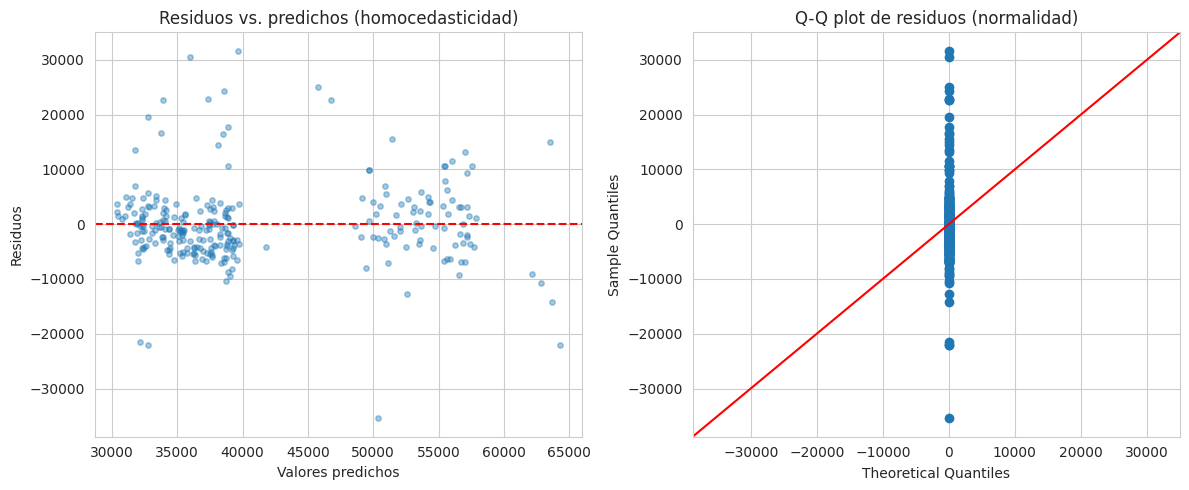

In [9]:
# --- 1.5 Gráficos de diagnóstico de residuos ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(predichos_h2, residuos_h2, alpha=0.4, s=15)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Valores predichos')
axes[0].set_ylabel('Residuos')
axes[0].set_title('Residuos vs. predichos (homocedasticidad)')

sm.qqplot(residuos_h2, line='45', ax=axes[1])
axes[1].set_title('Q-Q plot de residuos (normalidad)')

plt.tight_layout()
plt.show()

In [10]:
# --- 1.6 Si hay heterocedasticidad: versión robusta (errores estándar HC3) ---
if bp_p < 0.05:
    modelo_h2_robusto = modelo_h2.get_robustcov_results(cov_type='HC3')
    print(modelo_h2_robusto.summary())
else:
    print("No se detectó heterocedasticidad significativa; no es necesario el ajuste robusto.")

No se detectó heterocedasticidad significativa; no es necesario el ajuste robusto.


In [11]:
# --- 1.7 Conclusión -- H2 ---
nota_supuestos_h2 = []
if shapiro_p < 0.05:
    nota_supuestos_h2.append(
        f"los residuos no son perfectamente normales (esperable en datos de ventas; con {len(agg)} observaciones diarias "
        "el test F/t sigue siendo razonablemente robusto por el tamaño muestral, Teorema Central del Límite)"
    )
if bp_p < 0.05:
    nota_supuestos_h2.append(
        "se detectó heterocedasticidad, por lo que se reporta la versión robusta (HC3) como respaldo"
    )

display(Markdown(f'''
### Conclusión -- H2

{"Se rechaza" if significativo_h2 else "No se rechaza"} la hipótesis nula (p = {p_valor_temp:.5f}).
El coeficiente estimado de temperatura es **{coef_temp:.2f}** (dirección {direccion_h2}): por cada grado
adicional de temperatura promedio diaria, las ventas totales {"aumentan" if coef_temp > 0 else "disminuyen"}
en promedio **{abs(coef_temp):.1f} unidades**, controlando por fin de semana, feriado y mes.

El modelo explica un **{r2_ajustado_h2*100:.1f}%** de la variabilidad de las ventas diarias (R² ajustado).
Ese R² describe al **modelo completo** (dominado por el calendario), no al efecto de la temperatura; el tamaño del
efecto de la temperatura se mide aparte en la celda 1.3b (R² parcial).

**Supuestos:** {"; ".join(nota_supuestos_h2) if nota_supuestos_h2 else "no se detectaron violaciones relevantes."}
'''))



### Conclusión -- H2

No se rechaza la hipótesis nula (p = 0.25359).
El coeficiente estimado de temperatura es **-131.05** (dirección negativa): por cada grado
adicional de temperatura promedio diaria, las ventas totales disminuyen
en promedio **131.0 unidades**, controlando por fin de semana, feriado y mes.

El modelo explica un **58.5%** de la variabilidad de las ventas diarias (R² ajustado).
Ese R² describe al **modelo completo** (dominado por el calendario), no al efecto de la temperatura; el tamaño del
efecto de la temperatura se mide aparte en la celda 1.3b (R² parcial).

**Supuestos:** los residuos no son perfectamente normales (esperable en datos de ventas; con 271 observaciones diarias el test F/t sigue siendo razonablemente robusto por el tamaño muestral, Teorema Central del Límite)


# 2. H1 — Sección más sensible al clima, controlando por local

**H0 (nula):** las ventas promedio de la sección más sensible al clima son iguales entre los tres grupos climáticos (frío / templado / caluroso), controlando por local.

**H1 (alternativa):** al menos un grupo climático difiere en la venta promedio de esa sección, controlando por local.

**Nivel de significancia:** α = 0.05

In [12]:
# --- 2.1 Grupo climático (terciles de temperatura observada) ---
t_bajo, t_alto = df_final['temperatura'].quantile([1/3, 2/3])

def clasificar_clima(t):
    if pd.isna(t):
        return np.nan
    elif t <= t_bajo:
        return 'Frío'
    elif t <= t_alto:
        return 'Templado'
    else:
        return 'Caluroso'

df_final['grupo_climatico'] = df_final['temperatura'].apply(clasificar_clima)
print(f"Frío <= {t_bajo:.1f}°C | Templado | Caluroso > {t_alto:.1f}°C")

Frío <= 20.0°C | Templado | Caluroso > 24.9°C


In [13]:
# --- 2.2 Identificar la "sección más sensible" al clima ---
# Mismo criterio que en el EDA: variación % de venta promedio entre Caluroso y Frío,
# restringido a las secciones de mayor volumen (evita ruido estadístico de secciones chicas).
secciones_top = df_final['desc_secciones'].value_counts().head(10).index.tolist()

ventas_seccion_clima = (
    df_final[df_final['desc_secciones'].isin(secciones_top)]
    .groupby(['desc_secciones', 'grupo_climatico'], observed=True)['cantidad']
    .mean()
    .unstack()
)

ventas_seccion_clima['variacion_%'] = (
    (ventas_seccion_clima['Caluroso'] - ventas_seccion_clima['Frío']) / ventas_seccion_clima['Frío'] * 100
)

seccion_objetivo = ventas_seccion_clima['variacion_%'].abs().idxmax()
print(f"Sección más sensible al clima (mayor |variación %|): {seccion_objetivo}")
ventas_seccion_clima.sort_values('variacion_%', key=abs, ascending=False)

Sección más sensible al clima (mayor |variación %|): Bebidas


grupo_climatico,Caluroso,Frío,Templado,variacion_%
desc_secciones,,,,
Bebidas,1.466559,1.390688,1.462061,5.455595
Insumos,1.608696,1.538199,1.581774,4.583143
Produccion,1.059025,1.085062,1.075332,-2.399566
Hogar,0.885219,0.865493,0.879243,2.279148
Belleza y Salud,1.042171,1.027165,1.030895,1.460934
Perecederos,1.178838,1.163583,1.174094,1.310970
Limpieza,1.062996,1.050409,1.055643,1.198307
Tienda,1.012450,1.000494,1.006404,1.194994
Bazar,1.240152,1.254146,1.232367,-1.115773


In [14]:
# --- 2.3 Subconjunto de datos para la prueba ---
datos_h1 = df_final[df_final['desc_secciones'] == seccion_objetivo].copy()
datos_h1 = datos_h1.dropna(subset=['cantidad', 'grupo_climatico', 'local'])
print(f"Registros de '{seccion_objetivo}' con grupo climático asignado: {len(datos_h1):,}")
datos_h1.groupby(['grupo_climatico', 'local'], observed=True)['cantidad'].describe()[['count', 'mean', 'std']]

Registros de 'Bebidas' con grupo climático asignado: 427,689


count      mean       std
grupo_climatico local                                
Caluroso        Local X  111348.0  1.439665  2.171257
                Local Y   37484.0  1.546446  3.293884
Frío            Local X   72547.0  1.358843  5.914913
                Local Y   57183.0  1.431090  2.430951
Templado        Local X   89353.0  1.414444  2.080690
                Local Y   59774.0  1.533242  3.045189

In [15]:
# --- 2.4 Homogeneidad de varianzas (Levene) ---
grupos_h1 = [g['cantidad'].values for _, g in datos_h1.groupby('grupo_climatico', observed=True)]
levene_stat, levene_p = levene(*grupos_h1)
print(f"Test de Levene (homogeneidad de varianzas): estadístico={levene_stat:.3f}, p-valor={levene_p:.5f}")
print(f"  -> {'Varianzas NO homogéneas' if levene_p < 0.05 else 'No se rechaza homogeneidad'} (alpha=0.05)")

Test de Levene (homogeneidad de varianzas): estadístico=14.726, p-valor=0.00000


  -> Varianzas NO homogéneas (alpha=0.05)


In [16]:
# --- 2.5 Muestra para el modelo (rendimiento) ---
# Con volúmenes muy grandes, se toma una muestra aleatoria estratificada por
# grupo climático y local para que el ajuste sea rápido, sin alterar la conclusión
# (el n sigue siendo grande; además el ANOVA por sí solo ya es muy sensible con n grande,
#  por eso se reporta también el tamaño del efecto -- eta^2 -- en 2.7).
if len(datos_h1) > 300_000:
    # (se evita groupby.apply: en pandas >= 3 descarta las columnas de agrupación; este bucle da el mismo muestreo)
    datos_h1_modelo = pd.concat([
        g.sample(min(len(g), 100_000), random_state=42)
        for _, g in datos_h1.groupby(['grupo_climatico', 'local'], observed=True)
    ])
    print(f"Muestra para el modelo: {len(datos_h1_modelo):,} registros (de {len(datos_h1):,} totales)")
else:
    datos_h1_modelo = datos_h1

Muestra para el modelo: 416,341 registros (de 427,689 totales)


In [17]:
# --- 2.6 ANOVA de dos factores: grupo climático x local ---
modelo_h1 = smf.ols(
    'cantidad ~ C(grupo_climatico) + C(local) + C(grupo_climatico):C(local)',
    data=datos_h1_modelo
).fit()

tabla_anova_h1 = sm.stats.anova_lm(modelo_h1, typ=2)
tabla_anova_h1

,sum_sq,df,F,PR(>F)
C(grupo_climatico),6.515693e+02,2.0,28.926641,2.742788e-13
C(local),9.507211e+02,1.0,84.415172,4.028184e-20
C(grupo_climatico):C(local),3.898204e+01,2.0,1.730621,1.771757e-01
Residual,4.688950e+06,416335.0,NaN,NaN


In [18]:
# --- 2.7 Tamaño del efecto (eta^2) y resultado ---
ss_clima = tabla_anova_h1.loc['C(grupo_climatico)', 'sum_sq']
ss_total_h1 = tabla_anova_h1['sum_sq'].sum()
eta2_clima = ss_clima / ss_total_h1

p_clima = tabla_anova_h1.loc['C(grupo_climatico)', 'PR(>F)']
p_interaccion_h1 = tabla_anova_h1.loc['C(grupo_climatico):C(local)', 'PR(>F)']

significativo_h1 = p_clima < 0.05

def calificar_eta2(e):
    if e < 0.01:
        return 'efecto insignificante'
    elif e < 0.06:
        return 'efecto pequeño'
    elif e < 0.14:
        return 'efecto mediano'
    else:
        return 'efecto grande'

print(f"Efecto principal de grupo_climatico: p-valor = {p_clima:.5g}, eta² = {eta2_clima:.4f} ({calificar_eta2(eta2_clima)})")
print(f"Interacción clima x local: p-valor = {p_interaccion_h1:.5g}")

Efecto principal de grupo_climatico: p-valor = 2.7428e-13, eta² = 0.0001 (efecto insignificante)
Interacción clima x local: p-valor = 0.17718


In [19]:
# --- 2.8 Comparaciones post-hoc entre grupos climáticos (Tukey HSD) ---
tukey_h1 = pairwise_tukeyhsd(endog=datos_h1_modelo['cantidad'], groups=datos_h1_modelo['grupo_climatico'], alpha=0.05)
print(tukey_h1)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1   group2  meandiff p-adj   lower   upper  reject
--------------------------------------------------------
Caluroso     Frío  -0.0773    0.0 -0.1077 -0.0468   True
Caluroso Templado  -0.0059 0.8848 -0.0353  0.0235  False
    Frío Templado   0.0714    0.0  0.0415  0.1012   True
--------------------------------------------------------


In [20]:
# --- 2.8b IC 95% (Tukey), verificación de eta² y supuestos del ANOVA (H1) ---
# (a) IC 95% de la diferencia Caluroso - Frío, tomado de Tukey HSD (ya corrige por las 3 comparaciones).
tuk = tukey_h1.summary().data
tab_tukey = pd.DataFrame(tuk[1:], columns=tuk[0])
for c_ in ['meandiff', 'p-adj', 'lower', 'upper']:
    tab_tukey[c_] = tab_tukey[c_].astype(float)
fila_cf = tab_tukey[(tab_tukey['group1'] == 'Caluroso') & (tab_tukey['group2'] == 'Frío')].iloc[0]
# statsmodels reporta meandiff = media(group2) - media(group1) = Frío - Caluroso; se invierte el signo
dif_caluroso_frio = -float(fila_cf['meandiff'])
ic_tukey_h1 = (-float(fila_cf['upper']), -float(fila_cf['lower']))
p_tukey_h1 = float(fila_cf['p-adj'])
media_frio_h1 = datos_h1_modelo.loc[datos_h1_modelo['grupo_climatico'] == 'Frío', 'cantidad'].mean()
print(f"Diferencia Caluroso - Frío: {dif_caluroso_frio:+.4f} unidades por registro | IC95% Tukey [{ic_tukey_h1[0]:.4f}; {ic_tukey_h1[1]:.4f}] | p ajustado {'< 0.001' if p_tukey_h1 < 0.001 else '= ' + format(p_tukey_h1, '.3g')}")
print(f"   (equivale a {dif_caluroso_frio / media_frio_h1 * 100:+.2f}% sobre la media en días fríos: {media_frio_h1:.3f} unidades/registro)")

# (b) Verificación de eta²: SS del factor / SS total del modelo, y eta² parcial
ss_res_h1 = tabla_anova_h1.loc['Residual', 'sum_sq']
eta2_check_h1 = ss_clima / modelo_h1.centered_tss
eta2_parcial_h1 = ss_clima / (ss_clima + ss_res_h1)
print(f"eta² (celda 2.7) = {eta2_clima:.5f} | SS clima / SS total del modelo = {eta2_check_h1:.5f} | eta² parcial = {eta2_parcial_h1:.5f}")
print(f"   -> {'coinciden (cálculo correcto)' if abs(eta2_clima - eta2_check_h1) < 1e-4 else 'DIFIEREN: revisar'}")

# (c) Normalidad de residuos del ANOVA (muestra de 5000 por el límite de Shapiro) y forma de la distribución
res_h1 = modelo_h1.resid
shapiro_h1 = stats.shapiro(res_h1.sample(5000, random_state=42))
print(f"Shapiro-Wilk (muestra de 5000 residuos): p = {shapiro_h1.pvalue:.3g} | asimetría = {stats.skew(res_h1):.1f} | curtosis exceso = {stats.kurtosis(res_h1):.1f}")

# (d) Sensibilidad por dependencia: las filas del mismo día comparten clima, por lo que no son independientes.
#     Se repite la prueba del efecto de grupo climático con errores agrupados por fecha (igual lógica que H3/H5).
m_h1_cl = smf.ols('cantidad ~ C(grupo_climatico) + C(local)', data=datos_h1_modelo).fit(
    cov_type='cluster', cov_kwds={'groups': pd.factorize(datos_h1_modelo['fecha_vta'])[0]}, use_t=True)
nom_h1 = list(m_h1_cl.params.index)
idx_h1 = [i for i, n_ in enumerate(nom_h1) if 'grupo_climatico' in n_]
R_h1 = np.zeros((len(idx_h1), len(nom_h1)))
for k_, j_ in enumerate(idx_h1):
    R_h1[k_, j_] = 1
w_h1_cl = m_h1_cl.wald_test(R_h1, use_f=True, scalar=True)
f_h1_cl, p_h1_cl = float(w_h1_cl.statistic), float(w_h1_cl.pvalue)
print(f"Efecto de grupo climático con errores agrupados por fecha: F = {f_h1_cl:.2f}, p = {p_h1_cl:.3g}")


Diferencia Caluroso - Frío: +0.0773 unidades por registro | IC95% Tukey [0.0468; 0.1077] | p ajustado < 0.001
   (equivale a +5.56% sobre la media en días fríos: 1.391 unidades/registro)
eta² (celda 2.7) = 0.00014 | SS clima / SS total del modelo = 0.00014 | eta² parcial = 0.00014
   -> coinciden (cálculo correcto)
Shapiro-Wilk (muestra de 5000 residuos): p = 1.45e-89 | asimetría = 3.5 | curtosis exceso = 49715.0


Efecto de grupo climático con errores agrupados por fecha: F = 1.75, p = 0.176


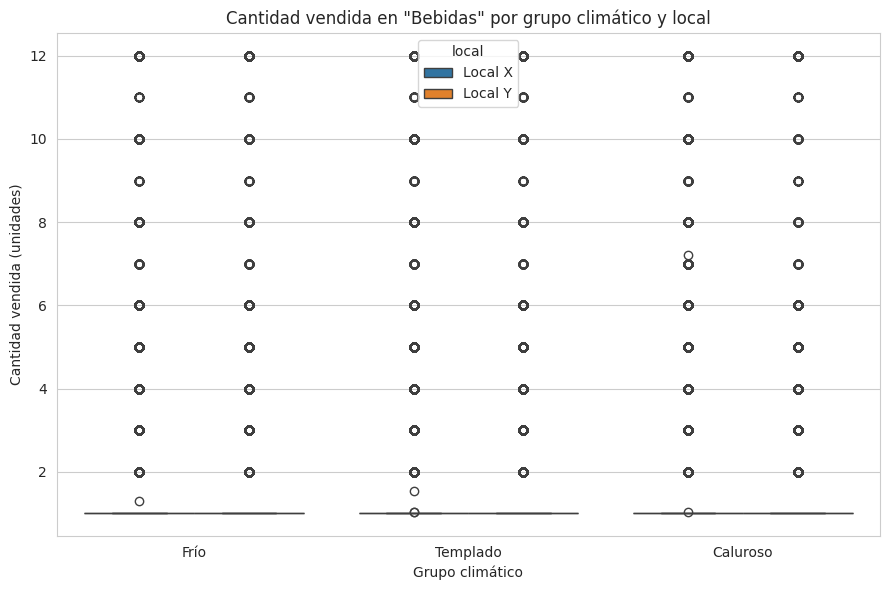

In [21]:
# --- 2.9 Gráfico de apoyo ---
fig, ax = plt.subplots(figsize=(9, 6))
orden_clima = ['Frío', 'Templado', 'Caluroso']
sns.boxplot(
    data=datos_h1_modelo[datos_h1_modelo['cantidad'].between(
        datos_h1_modelo['cantidad'].quantile(0.01), datos_h1_modelo['cantidad'].quantile(0.99)
    )],
    x='grupo_climatico', y='cantidad', hue='local', order=orden_clima, ax=ax
)
ax.set_title(f'Cantidad vendida en "{seccion_objetivo}" por grupo climático y local')
ax.set_xlabel('Grupo climático')
ax.set_ylabel('Cantidad vendida (unidades)')
plt.tight_layout()
plt.show()

In [22]:
# --- 2.10 Conclusión -- H1 ---
nota_supuestos_h1 = []
if levene_p < 0.05:
    nota_supuestos_h1.append(
        "las varianzas no son homogéneas entre grupos climáticos, lo que relativiza el ANOVA clásico; "
        "el resultado de Tukey HSD (que no asume varianzas iguales en su variante robusta) refuerza la lectura"
    )

display(Markdown(f'''
### Conclusión -- H1

Sección analizada: **{seccion_objetivo}**.

{"Se rechaza" if significativo_h1 else "No se rechaza"} la hipótesis nula para el efecto principal de grupo climático
(p = {p_clima:.5g}), con un tamaño de efecto **{calificar_eta2(eta2_clima)}** (eta² = {eta2_clima:.4f}).
La interacción clima x local {"es significativa (p = " + f"{p_interaccion_h1:.5g}" + "), es decir, el efecto del clima no es igual en ambos locales" if p_interaccion_h1 < 0.05 else "no es significativa (p = " + f"{p_interaccion_h1:.5g}" + "), es decir, el patrón climático se repite de forma similar en ambos locales"}.

Las comparaciones Tukey HSD (celda anterior) indican qué pares de grupos climáticos difieren entre sí específicamente.

**Supuestos:** {"; ".join(nota_supuestos_h1) if nota_supuestos_h1 else "no se detectaron violaciones relevantes (varianzas homogéneas según Levene)."}

**Nota sobre el tamaño muestral:** con cientos de miles de registros, el ANOVA puede marcar significancia
estadística aunque la diferencia práctica sea chica -- por eso la lectura final se apoya en el **eta²**
(tamaño del efecto), no solo en el p-valor.
'''))


### Conclusión -- H1

Sección analizada: **Bebidas**.

Se rechaza la hipótesis nula para el efecto principal de grupo climático
(p = 2.7428e-13), con un tamaño de efecto **efecto insignificante** (eta² = 0.0001).
La interacción clima x local no es significativa (p = 0.17718), es decir, el patrón climático se repite de forma similar en ambos locales.

Las comparaciones Tukey HSD (celda anterior) indican qué pares de grupos climáticos difieren entre sí específicamente.

**Supuestos:** las varianzas no son homogéneas entre grupos climáticos, lo que relativiza el ANOVA clásico; el resultado de Tukey HSD (que no asume varianzas iguales en su variante robusta) refuerza la lectura

**Nota sobre el tamaño muestral:** con cientos de miles de registros, el ANOVA puede marcar significancia
estadística aunque la diferencia práctica sea chica -- por eso la lectura final se apoya en el **eta²**
(tamaño del efecto), no solo en el p-valor.


In [23]:
# --- 2.11 Robustez de la conclusión de H1 ante la dependencia entre filas ---
robusta_h1 = p_h1_cl < 0.05
if robusta_h1:
    texto_lectura_h1 = "la conclusión de rechazar H0 se mantiene al agrupar los errores por fecha."
else:
    texto_lectura_h1 = (f"la significancia del ANOVA clásico (p = {p_clima:.2g}) NO se sostiene al considerar la dependencia: con errores agrupados "
                        "por fecha no se rechaza H0. El resultado clásico se conserva arriba, pero debe leerse como no robusto; sumado al eta² "
                        "insignificante, H1 no aporta evidencia sólida de un efecto climático sobre la sección más sensible.")
display(Markdown(f'''
### Robustez de la conclusión de H1

El ANOVA clásico trata cada una de las {len(datos_h1_modelo):,} filas como independiente, pero el grupo climático se asigna por día y estación: todas las filas
de un mismo día y local comparten el mismo grupo. Son pocas fechas ({datos_h1_modelo['fecha_vta'].nunique()}) repetidas muchas veces (pseudo-replicación), y el
p-valor clásico refleja el número de filas más que el número de días. Con errores estándar agrupados por fecha (celda 2.8b), el efecto del grupo
climático da F = {f_h1_cl:.2f}, p = {p_h1_cl:.3g}.

**Lectura:** {texto_lectura_h1}
'''))



### Robustez de la conclusión de H1

El ANOVA clásico trata cada una de las 416,341 filas como independiente, pero el grupo climático se asigna por día y estación: todas las filas
de un mismo día y local comparten el mismo grupo. Son pocas fechas (271) repetidas muchas veces (pseudo-replicación), y el
p-valor clásico refleja el número de filas más que el número de días. Con errores estándar agrupados por fecha (celda 2.8b), el efecto del grupo
climático da F = 1.75, p = 0.176.

**Lectura:** la significancia del ANOVA clásico (p = 2.7e-13) NO se sostiene al considerar la dependencia: con errores agrupados por fecha no se rechaza H0. El resultado clásico se conserva arriba, pero debe leerse como no robusto; sumado al eta² insignificante, H1 no aporta evidencia sólida de un efecto climático sobre la sección más sensible.


# 3. Preparación común para H3 y H4

In [24]:
# --- 3.0 Librerías adicionales y variables de apoyo ---
from statsmodels.stats.multitest import multipletests

# Grupo climático (mismos terciles que en H1; se recalcula por si esta sección se corre sola).
# pd.cut vectorizado: equivale al .apply() de H1 (intervalos cerrados a la derecha, <=) pero mucho más rápido en 9.4M filas.
t_bajo, t_alto = df_final['temperatura'].quantile([1/3, 2/3])
df_final['grupo_climatico'] = pd.cut(
    df_final['temperatura'], bins=[-np.inf, t_bajo, t_alto, np.inf],
    labels=['Frío', 'Templado', 'Caluroso']
)
print(f"Frío <= {t_bajo:.1f}°C | Templado | Caluroso > {t_alto:.1f}°C")

# Calendario y temperatura por (fecha, local). La temperatura depende de la estación asignada al local,
# así que es constante dentro de cada (fecha, local).
cal_dia_local = (
    df_final.groupby(['fecha_vta', 'local'], observed=True)
    .agg(temperatura=('temperatura', 'mean'),
         es_fin_de_semana=('es_fin_de_semana', 'first'),
         es_feriado=('es_feriado', 'first'),
         mes=('mes', 'first'))
    .reset_index()
)
cal_dia_local['local'] = cal_dia_local['local'].astype(str)
print(f"Combinaciones fecha x local: {len(cal_dia_local):,} "
      f"({cal_dia_local['fecha_vta'].nunique()} fechas, {cal_dia_local['local'].nunique()} locales)")

Frío <= 20.0°C | Templado | Caluroso > 24.9°C


Combinaciones fecha x local: 540 (271 fechas, 2 locales)


# 4. H3 — El efecto del clima difiere entre secciones comerciales

**H0 (nula):** la pendiente de la temperatura sobre las ventas es la misma en todas las secciones (no hay interacción temperatura × sección).

**H1 (alternativa):** al menos una sección tiene una pendiente de temperatura distinta de las demás.

**Nivel de significancia:** α = 0.05

**Decisiones de diseño (y por qué):**
- **Unidad de análisis = cantidad total por fecha × local × sección** (no la transacción). En el nivel transaccional `cantidad` es casi siempre 1 (IQR = 0) y tiene extremos de ±40,500; ahí cualquier modelo termina midiendo ruido. Agregar por día produce una variable continua, y el clima (que es diario) pasa a ser la unidad natural.
- **Variable respuesta = log(cantidad diaria).** Las secciones difieren en órdenes de magnitud de volumen; en logaritmos el coeficiente de temperatura se lee como **% de cambio por °C** y es comparable entre secciones.
- **Se controla por calendario** (fin de semana y feriado, con efecto propio por sección; mes; local), igual que en H2.
- **Errores estándar agrupados por fecha.** Todas las secciones y locales de un mismo día comparten el mismo clima y calendario, por lo que las filas no son independientes. Sin esto, los p-valores serían optimistas.

In [25]:
# --- 4.1 Panel fecha x local x sección ---
def armar_panel(df, col_grupo, grupos, umbral_extremo=None):
    '''Cantidad total por (fecha, local, grupo), completando con 0 los días sin venta del grupo.'''
    base = df[df[col_grupo].isin(grupos)]
    if umbral_extremo is not None:
        base = base[base['cantidad'].abs() <= umbral_extremo]
    ventas = (base.groupby(['fecha_vta', 'local', col_grupo], observed=True)['cantidad']
              .sum().rename('cantidad_dia').reset_index())
    ventas['local'] = ventas['local'].astype(str)
    ventas[col_grupo] = ventas[col_grupo].astype(str)

    grid = cal_dia_local.merge(pd.DataFrame({col_grupo: [str(g) for g in grupos]}), how='cross')
    panel = grid.merge(ventas, on=['fecha_vta', 'local', col_grupo], how='left')
    panel['cantidad_dia'] = panel['cantidad_dia'].fillna(0.0)

    n_antes = len(panel)
    panel = panel[panel['cantidad_dia'] > 0].copy()      # log requiere > 0 (días sin venta o neto negativo por devoluciones)
    print(f"Celdas fecha x local x grupo: {n_antes:,} | descartadas por venta diaria <= 0: {n_antes - len(panel):,}")

    panel['log_cant'] = np.log(panel['cantidad_dia'])
    panel['temp_c'] = panel['temperatura'] - panel['temperatura'].mean()   # temperatura centrada
    panel['grupo_climatico'] = pd.cut(panel['temperatura'], bins=[-np.inf, t_bajo, t_alto, np.inf],
                                      labels=['Frío', 'Templado', 'Caluroso'])
    return panel.reset_index(drop=True)

def ajustar(formula, datos):
    '''OLS con errores estándar robustos agrupados por fecha.'''
    grupos_fecha = pd.factorize(datos['fecha_vta'])[0]
    return smf.ols(formula, data=datos).fit(cov_type='cluster', cov_kwds={'groups': grupos_fecha})

# Secciones con volumen suficiente (excluye Hogar, Servicios, Perecederos Terceros, que son casi vacías)
MIN_REGISTROS = 100_000
conteo_sec = df_final['desc_secciones'].value_counts()
secciones_h3 = conteo_sec[conteo_sec >= MIN_REGISTROS].index.tolist()
print("Secciones incluidas:", secciones_h3)

panel_h3 = armar_panel(df_final, 'desc_secciones', secciones_h3)
print(f"Panel H3: {len(panel_h3):,} observaciones")
panel_h3.groupby('desc_secciones')['cantidad_dia'].describe()[['count', 'mean', 'std', 'min', 'max']]

Secciones incluidas: ['Perecederos ', 'Almacen', 'Produccion', 'Limpieza', 'Bazar', 'Bebidas', 'Belleza y Salud', 'Insumos', 'Tienda']


Celdas fecha x local x grupo: 4,860 | descartadas por venta diaria <= 0: 0
Panel H3: 4,860 observaciones


,count,mean,std,min,max
desc_secciones,,,,,
Almacen,540.0,4883.361781,2482.028724,368.830,13091.7344
Bazar,540.0,1178.726355,548.042612,52.455,3855.2800
Bebidas,540.0,1142.069815,689.254773,100.000,4405.0000
Belleza y Salud,540.0,720.920370,409.844809,19.000,2261.0000
Insumos,540.0,678.604352,817.122512,46.000,4116.0000
Limpieza,540.0,1048.703043,556.894397,79.665,3292.5800
Perecederos,540.0,8288.151406,4106.019776,652.820,21790.1004
Produccion,540.0,2327.681153,1136.269677,222.710,5348.9829
Tienda,540.0,282.629630,127.215082,13.000,992.0000


In [26]:
# --- 4.2 Test principal: ¿la pendiente de temperatura depende de la sección? ---
# Modelo restringido: una pendiente común de temperatura para todas las secciones.
# Modelo completo: pendiente propia por sección (interacción temp_c x sección).
ctrl = 'C(desc_secciones) * (es_fin_de_semana + es_feriado) + C(mes) + C(local)'
modelo_h3_restr = ajustar(f'log_cant ~ temp_c + {ctrl}', panel_h3)
modelo_h3_full  = ajustar(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', panel_h3)

# Test de Wald conjunto (robusto, agrupado por fecha) sobre los términos de interacción
nombres = list(modelo_h3_full.params.index)
idx_int = [i for i, n in enumerate(nombres) if ':' in n and 'temp_c' in n]
R = np.zeros((len(idx_int), len(nombres)))
for fila, j in enumerate(idx_int):
    R[fila, j] = 1
wald_h3 = modelo_h3_full.wald_test(R, use_f=True, scalar=True)
f_h3, p_h3 = float(wald_h3.statistic), float(wald_h3.pvalue)

# Tamaño de efecto: R² parcial de la interacción (con ajuste MCO clásico, solo para la descomposición de varianza)
m_r = smf.ols(f'log_cant ~ temp_c + {ctrl}', data=panel_h3).fit()
m_f = smf.ols(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', data=panel_h3).fit()
r2_parcial_h3 = (m_r.ssr - m_f.ssr) / m_r.ssr
f_clasico, p_clasico, _ = m_f.compare_f_test(m_r)

significativo_h3 = p_h3 < 0.05
print(f"Interacción temperatura x sección (Wald F robusto, agrupado por fecha): F = {f_h3:.2f}, p = {p_h3:.3g}")
print(f"Referencia, F clásico (supone independencia):                          F = {f_clasico:.2f}, p = {p_clasico:.3g}")
print(f"R² parcial de la interacción: {r2_parcial_h3:.4f}")

Interacción temperatura x sección (Wald F robusto, agrupado por fecha): F = 50.26, p = 3.17e-49
Referencia, F clásico (supone independencia):                          F = 26.19, p = 5.15e-40
R² parcial de la interacción: 0.0417


In [27]:
# --- 4.2b Verificación de supuestos (H3) ---
# Modelo clásico completo (m_f, celda 4.2): se examinan sus residuos. La inferencia principal ya usa errores
# agrupados por fecha (robustos a heterocedasticidad y a correlación entre filas del mismo día).
res_h3 = pd.Series(m_f.resid.values, index=panel_h3.index)

# Normalidad (n = 4,860 < 5,000, se usa toda la muestra)
sh_h3 = stats.shapiro(res_h3.sample(min(5000, len(res_h3)), random_state=42))
# Homocedasticidad
bp_h3 = het_breuschpagan(m_f.resid, m_f.model.exog)
# Multicolinealidad: efectos principales (sin interacciones, que inflan el VIF por construcción)
mm_h3 = smf.ols('log_cant ~ temp_c + es_fin_de_semana + es_feriado + C(local) + C(mes)', data=panel_h3).fit().model
vif_h3 = pd.DataFrame({'variable': mm_h3.exog_names,
                       'VIF': [variance_inflation_factor(mm_h3.exog, i) for i in range(mm_h3.exog.shape[1])]})
vif_h3 = vif_h3[vif_h3['variable'] != 'Intercept']
vif_temp_h3 = float(vif_h3.loc[vif_h3['variable'] == 'temp_c', 'VIF'].iloc[0])
vif_max_h3 = float(vif_h3['VIF'].max())
var_vif_max_h3 = vif_h3.loc[vif_h3['VIF'].idxmax(), 'variable']
# Independencia: parte de la varianza de los residuos que es "entre fechas" (si fueran independientes ≈ (G-1)/(n-1))
n_h3, g_h3 = len(res_h3), panel_h3['fecha_vta'].nunique()
entre_fechas_h3 = float((res_h3.groupby(panel_h3['fecha_vta']).transform('mean') ** 2).sum() / (res_h3 ** 2).sum())
esperado_indep_h3 = (g_h3 - 1) / (n_h3 - 1)

print(f"Shapiro-Wilk: W = {sh_h3.statistic:.4f}, p = {sh_h3.pvalue:.3g} -> {'residuos NO normales' if sh_h3.pvalue < 0.05 else 'No se rechaza normalidad'}")
print(f"Breusch-Pagan: LM = {bp_h3[0]:.2f}, p = {bp_h3[1]:.3g} -> {'HAY heterocedasticidad' if bp_h3[1] < 0.05 else 'No se rechaza homocedasticidad'}")
print(f"VIF (efectos principales): temp_c = {vif_temp_h3:.2f}; máximo = {vif_max_h3:.2f} ({var_vif_max_h3})")
print(f"Independencia: {entre_fechas_h3*100:.1f}% de la varianza residual es 'entre fechas' vs. {esperado_indep_h3*100:.1f}% esperado si las filas fueran independientes")
print("Lectura: con n grande la no normalidad pesa poco; la heterocedasticidad y la dependencia entre filas del mismo día "
      "se manejan con errores estándar agrupados por fecha, que es lo que usa el test de 4.2.")


Shapiro-Wilk: W = 0.8943, p = 1.24e-49 -> residuos NO normales
Breusch-Pagan: LM = 1436.20, p = 2.62e-272 -> HAY heterocedasticidad
VIF (efectos principales): temp_c = 1.85; máximo = 2.38 (C(mes)[T.7])
Independencia: 21.1% de la varianza residual es 'entre fechas' vs. 5.6% esperado si las filas fueran independientes
Lectura: con n grande la no normalidad pesa poco; la heterocedasticidad y la dependencia entre filas del mismo día se manejan con errores estándar agrupados por fecha, que es lo que usa el test de 4.2.


In [28]:
# --- 4.3 ¿Qué secciones se mueven con el clima? Pendiente por sección ---
def pendientes_por_grupo(panel, col_grupo, con_mes=True):
    filas = []
    for g, d in panel.groupby(col_grupo):
        d = d.reset_index(drop=True)
        f = 'log_cant ~ temp_c + es_fin_de_semana + es_feriado + C(local)' + (' + C(mes)' if con_mes else '')
        m = ajustar(f, d)
        b = m.params['temp_c']
        lo, hi = m.conf_int().loc['temp_c']
        filas.append({col_grupo: g, 'n_obs': len(d), 'coef': b, 'p_valor': m.pvalues['temp_c'],
                      'efecto_%_por_°C': (np.exp(b) - 1) * 100,
                      'IC95_inf_%': (np.exp(lo) - 1) * 100, 'IC95_sup_%': (np.exp(hi) - 1) * 100})
    tabla = pd.DataFrame(filas)
    tabla['p_holm'] = multipletests(tabla['p_valor'], method='holm')[1]   # corrección por comparaciones múltiples
    tabla['signif_holm'] = tabla['p_holm'] < 0.05
    return tabla.sort_values('efecto_%_por_°C', ascending=False).reset_index(drop=True)

tabla_h3 = pendientes_por_grupo(panel_h3, 'desc_secciones')
# Sensibilidad: sin controlar por mes (la temperatura pasa a capturar también la estacionalidad)
sin_mes = pendientes_por_grupo(panel_h3, 'desc_secciones', con_mes=False)[['desc_secciones', 'efecto_%_por_°C']]
tabla_h3 = tabla_h3.merge(sin_mes.rename(columns={'efecto_%_por_°C': 'efecto_%_sin_control_mes'}), on='desc_secciones')
tabla_h3.round(4)

,desc_secciones,n_obs,coef,p_valor,efecto_%_por_°C,IC95_inf_%,IC95_sup_%,p_holm,signif_holm,efecto_%_sin_control_mes
0,Bebidas,540,0.0130,0.0255,1.3074,0.1590,2.4690,0.1533,False,2.5117
1,Limpieza,540,-0.0005,0.9047,-0.0502,-0.8689,0.7752,0.9047,False,1.0241
2,Perecederos,540,-0.0029,0.3982,-0.2872,-0.9502,0.3803,0.7964,False,0.6053
3,Belleza y Salud,540,-0.0057,0.2629,-0.5637,-1.5429,0.4252,0.7886,False,0.4333
4,Bazar,540,-0.0085,0.0603,-0.8425,-1.7139,0.0366,0.2703,False,0.0476
5,Insumos,540,-0.0092,0.0541,-0.9167,-1.8408,0.0161,0.2703,False,-3.5688
6,Produccion,540,-0.0100,0.0017,-0.9931,-1.6084,-0.3740,0.0129,True,-0.7330
7,Almacen,540,-0.0116,0.0016,-1.1559,-1.8677,-0.4388,0.0129,True,-0.7613
8,Tienda,540,-0.0220,0.0000,-2.1740,-3.0853,-1.2542,0.0000,True,-1.4178


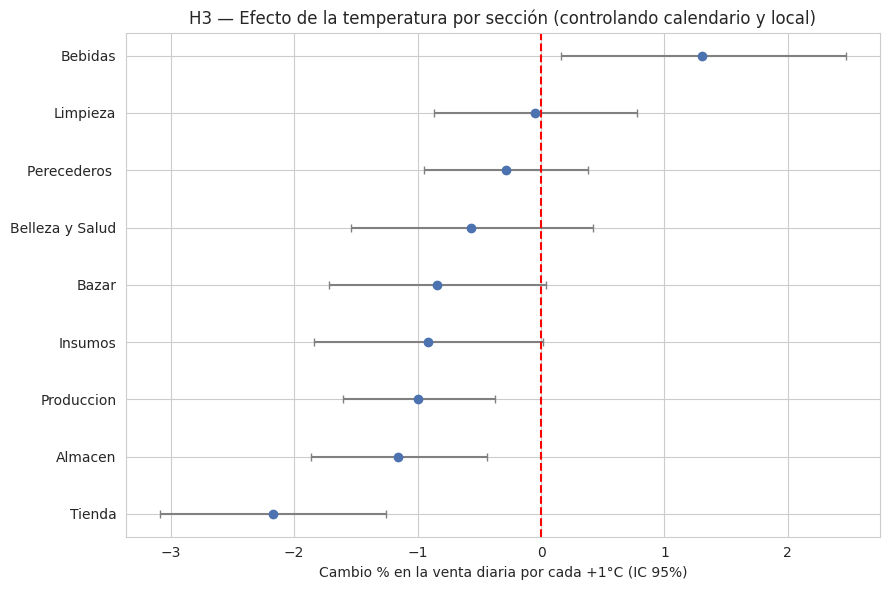

In [29]:
# --- 4.4 Gráfico: efecto de +1°C por sección (con IC 95%) ---
t = tabla_h3.sort_values('efecto_%_por_°C')
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(t['efecto_%_por_°C'], range(len(t)),
            xerr=[t['efecto_%_por_°C'] - t['IC95_inf_%'], t['IC95_sup_%'] - t['efecto_%_por_°C']],
            fmt='o', color='#4C72B0', ecolor='gray', capsize=3)
ax.axvline(0, color='red', linestyle='--')
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t['desc_secciones'])
ax.set_xlabel('Cambio % en la venta diaria por cada +1°C (IC 95%)')
ax.set_title('H3 — Efecto de la temperatura por sección (controlando calendario y local)')
plt.tight_layout()
plt.show()

In [30]:
# --- 4.5 ANOVA de dos vías complementario: grupo climático x sección (el método sugerido en el plan) ---
modelo_anova_h3 = smf.ols('log_cant ~ C(grupo_climatico) * C(desc_secciones)', data=panel_h3).fit()
anova_h3 = sm.stats.anova_lm(modelo_anova_h3, typ=2)
anova_h3['eta2_parcial'] = anova_h3['sum_sq'] / (anova_h3['sum_sq'] + anova_h3.loc['Residual', 'sum_sq'])
anova_h3.loc['Residual', 'eta2_parcial'] = np.nan
print("Nota: este ANOVA no controla calendario ni agrupa por fecha; es un respaldo, la inferencia principal es 4.2.")
anova_h3

Nota: este ANOVA no controla calendario ni agrupa por fecha; es un respaldo, la inferencia principal es 4.2.


,sum_sq,df,F,PR(>F),eta2_parcial
C(grupo_climatico),25.020685,2.0,36.307272,2.234778e-16,0.014802
C(desc_secciones),5193.826377,8.0,1884.177688,0.000000e+00,0.757214
C(grupo_climatico):C(desc_secciones),39.665754,16.0,7.194824,7.991717e-17,0.023265
Residual,1665.299605,4833.0,NaN,NaN,NaN


In [31]:
# --- 4.6 Sensibilidad a valores extremos ---
# En 'cantidad' hay registros de hasta ±40,500 (probables errores de carga); se repite el test sin |cantidad| > p99.9.
umbral = df_final['cantidad'].abs().quantile(0.999)
panel_h3_s = armar_panel(df_final, 'desc_secciones', secciones_h3, umbral_extremo=umbral)
m_s = ajustar(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', panel_h3_s)
nom_s = list(m_s.params.index)
idx_s = [i for i, n in enumerate(nom_s) if ':' in n and 'temp_c' in n]
R_s = np.zeros((len(idx_s), len(nom_s)))
for fila, j in enumerate(idx_s):
    R_s[fila, j] = 1
w_s = m_s.wald_test(R_s, use_f=True, scalar=True)
f_s, p_s = float(w_s.statistic), float(w_s.pvalue)
print(f"Sin extremos (|cantidad| <= {umbral:.1f}): F = {f_s:.2f}, p = {p_s:.3g}")
print(f"Conclusión {'se mantiene' if (p_s < 0.05) == significativo_h3 else 'CAMBIA'} respecto del análisis principal.")

Celdas fecha x local x grupo: 4,860 | descartadas por venta diaria <= 0: 0
Sin extremos (|cantidad| <= 14.5): F = 51.25, p = 6.67e-50
Conclusión se mantiene respecto del análisis principal.


In [32]:
# --- 4.7 Exploratorio: sustitución dentro de 'Bebidas' (por subsección) ---
# Idea del plan original: bebidas frías vs. calientes. Se mira a nivel desc_sub_secciones.
# Es exploratorio (muchas subsecciones, sin hipótesis fijada de antemano): se reporta con corrección de Holm.
bebidas = df_final[df_final['desc_secciones'] == 'Bebidas']
conteo_sub = bebidas['desc_sub_secciones'].value_counts()
print(conteo_sub.head(15))

subs = conteo_sub[conteo_sub >= 20_000].index.tolist()
if len(subs) >= 2:
    panel_sub = armar_panel(bebidas, 'desc_sub_secciones', subs)
    tabla_sub = pendientes_por_grupo(panel_sub, 'desc_sub_secciones')
    display(tabla_sub.round(4))
else:
    print("Hay menos de 2 subsecciones con volumen suficiente; se omite este análisis.")

desc_sub_secciones
Sin Alcohol                    355767
Con Alcohol                     71922
Accesorio Limpieza                  0
Aceites                             0
Arroz                               0
Articulos de Papel                  0
Articulos p/Bebe                    0
Atomatados/Salsas de Tomate         0
Azucar                              0
Bazar                               0
Bebe                                0
Belleza y Salud                     0
Bijouterie                          0
Bolsas                              0
Cafe/Cocido/Filtros                 0
Name: count, dtype: int64
Celdas fecha x local x grupo: 1,080 | descartadas por venta diaria <= 0: 0


,desc_sub_secciones,n_obs,coef,p_valor,efecto_%_por_°C,IC95_inf_%,IC95_sup_%,p_holm,signif_holm
0,Sin Alcohol,540,0.0120,0.0016,1.2051,0.4552,1.9606,0.0032,True
1,Con Alcohol,540,0.0114,0.3052,1.1428,-1.0305,3.3639,0.3052,False


In [33]:
# --- 4.8 Conclusión -- H3 ---
n_pos = int(((tabla_h3['efecto_%_por_°C'] > 0) & tabla_h3['signif_holm']).sum())
n_neg = int(((tabla_h3['efecto_%_por_°C'] < 0) & tabla_h3['signif_holm']).sum())
mayor = tabla_h3.iloc[0]
menor = tabla_h3.iloc[-1]

display(Markdown(f'''
### Conclusión -- H3

{"Se rechaza" if significativo_h3 else "No se rechaza"} la hipótesis nula de pendiente común (Wald F = {f_h3:.2f}, p = {p_h3:.3g}; agrupado por fecha).
La interacción temperatura × sección aporta un R² parcial de **{r2_parcial_h3:.4f}**.

Secciones con efecto significativo tras la corrección de Holm: **{n_pos}** positivo(s) y **{n_neg}** negativo(s).
Mayor efecto positivo: **{mayor["desc_secciones"]}** ({mayor["efecto_%_por_°C"]:+.2f}% por °C, IC95 [{mayor["IC95_inf_%"]:.2f}; {mayor["IC95_sup_%"]:.2f}]).
Mayor efecto negativo: **{menor["desc_secciones"]}** ({menor["efecto_%_por_°C"]:+.2f}% por °C, IC95 [{menor["IC95_inf_%"]:.2f}; {menor["IC95_sup_%"]:.2f}]).
{"Hay secciones con signos opuestos, patrón compatible con sustitución entre categorías." if (n_pos > 0 and n_neg > 0) else "No hay secciones con signos opuestos y significativos, por lo que la evidencia de sustitución es débil."}

**Sensibilidad:** sin valores extremos, el test de interacción da p = {p_s:.3g}; la conclusión {"se mantiene" if (p_s < 0.05) == significativo_h3 else "cambia"}.

**Limitaciones:** (i) 1 solo año parcial (enero-septiembre 2021), igual que en H2; (ii) con el control por mes, el efecto de la temperatura se identifica por las variaciones día a día dentro de cada mes, no por la estacionalidad (ver columna *sin_control_mes*); (iii) 2 locales y dos estaciones meteorológicas, es decir poca variación climática independiente.
'''))


### Conclusión -- H3

Se rechaza la hipótesis nula de pendiente común (Wald F = 50.26, p = 3.17e-49; agrupado por fecha).
La interacción temperatura × sección aporta un R² parcial de **0.0417**.

Secciones con efecto significativo tras la corrección de Holm: **0** positivo(s) y **3** negativo(s).
Mayor efecto positivo: **Bebidas** (+1.31% por °C, IC95 [0.16; 2.47]).
Mayor efecto negativo: **Tienda** (-2.17% por °C, IC95 [-3.09; -1.25]).
No hay secciones con signos opuestos y significativos, por lo que la evidencia de sustitución es débil.

**Sensibilidad:** sin valores extremos, el test de interacción da p = 6.67e-50; la conclusión se mantiene.

**Limitaciones:** (i) 1 solo año parcial (enero-septiembre 2021), igual que en H2; (ii) con el control por mes, el efecto de la temperatura se identifica por las variaciones día a día dentro de cada mes, no por la estacionalidad (ver columna *sin_control_mes*); (iii) 2 locales y dos estaciones meteorológicas, es decir poca variación climática independiente.


# 5. H4 — El fin de semana modera el efecto climático

**H0 (nula):** el coeficiente de la interacción `temperatura × es_fin_de_semana` es igual a 0 (la pendiente de la temperatura es la misma en días hábiles y fines de semana).

**H1 (alternativa):** el coeficiente de la interacción es distinto de 0 (el fin de semana amplifica o atenúa el efecto climático).

**Nivel de significancia:** α = 0.05

**Método:** extensión del modelo de H2 con el término de interacción: `cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes)`, sobre la serie diaria. La temperatura se **centra** (`temp_c`) para que el coeficiente de `es_fin_de_semana` se lea a la temperatura media y no a 0°C, lo cual no tendría sentido.

In [34]:
# --- 5.1 Serie diaria y modelo con interacción ---
agg_h4 = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean'),
    mes=('mes', 'first'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
).reset_index()
agg_h4['es_fin_de_semana'] = agg_h4['es_fin_de_semana'].astype(int)
agg_h4['es_feriado'] = agg_h4['es_feriado'].astype(int)
agg_h4['temp_c'] = agg_h4['temperatura_promedio'] - agg_h4['temperatura_promedio'].mean()

print(f"Observaciones (días): {len(agg_h4)} | fines de semana: {agg_h4['es_fin_de_semana'].sum()} | hábiles: {(agg_h4['es_fin_de_semana'] == 0).sum()}")

formula_h4 = 'cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes)'
modelo_h4 = smf.ols(formula_h4, data=agg_h4).fit()
modelo_h4_hc3 = smf.ols(formula_h4, data=agg_h4).fit(cov_type='HC3')

def nombre_interaccion(modelo):
    '''Busca en los coeficientes del modelo el término temp_c x es_fin_de_semana (patsy puede invertir el orden).'''
    cand = [n for n in modelo.params.index if ':' in str(n) and 'temp_c' in str(n) and 'es_fin_de_semana' in str(n)]
    if not cand:
        raise KeyError(f"No se encontró la interacción. Coeficientes disponibles: {list(modelo.params.index)}")
    return cand[0]

term = nombre_interaccion(modelo_h4)
print('Término de interacción detectado:', term)
ci_hc3 = modelo_h4_hc3.conf_int()
ci_cl = modelo_h4.conf_int()
resumen_h4 = pd.DataFrame({
    'coef': [modelo_h4.params[term]] * 2,
    'p_valor': [modelo_h4.pvalues[term], modelo_h4_hc3.pvalues[term]],
    'IC95_inf': [np.asarray(ci_cl.loc[term])[0], np.asarray(ci_hc3.loc[term])[0]],
    'IC95_sup': [np.asarray(ci_cl.loc[term])[1], np.asarray(ci_hc3.loc[term])[1]],
}, index=['MCO clásico', 'HC3 (robusto)'])
print(f"R² ajustado: {modelo_h4.rsquared_adj:.3f}")
resumen_h4.round(4)

Observaciones (días): 271 | fines de semana: 78 | hábiles: 193
Término de interacción detectado: temp_c:es_fin_de_semana
R² ajustado: 0.583


,coef,p_valor,IC95_inf,IC95_sup
MCO clásico,25.2759,0.8992,-367.1978,417.7496
HC3 (robusto),25.2759,0.9105,-415.6265,466.1784


In [35]:
# --- 5.2 Pendientes simples: efecto de +1°C en día hábil vs. fin de semana ---
t_habil = modelo_h4_hc3.t_test('temp_c = 0')
contraste = np.zeros(len(modelo_h4_hc3.params))
contraste[list(modelo_h4_hc3.params.index).index('temp_c')] = 1
contraste[list(modelo_h4_hc3.params.index).index(term)] = 1
t_finde = modelo_h4_hc3.t_test(contraste)   # pendiente en fin de semana = temp_c + interacción

def fila(nombre, t):
    lo, hi = np.asarray(t.conf_int()).ravel()[:2]
    return {'día': nombre, 'unidades_por_°C': float(t.effect[0]), 'IC95_inf': lo, 'IC95_sup': hi, 'p_valor': float(t.pvalue)}

pendientes_h4 = pd.DataFrame([fila('Día hábil', t_habil), fila('Fin de semana', t_finde)]).set_index('día')
pendientes_h4.round(4)

,unidades_por_°C,IC95_inf,IC95_sup,p_valor
día,,,,
Día hábil,-136.8161,-353.7528,80.1206,0.2164
Fin de semana,-111.5402,-563.3239,340.2435,0.6285


In [36]:
# --- 5.2b Tamaño del efecto de la interacción (H4) ---
# R² parcial de la interacción: cuánto de la variabilidad residual del modelo sin interacción explica el término.
m_h4_sin_int = smf.ols('cantidad_total ~ temp_c + es_fin_de_semana + es_feriado + C(mes)', data=agg_h4).fit()
r2_parcial_h4 = (m_h4_sin_int.ssr - modelo_h4.ssr) / m_h4_sin_int.ssr
f2_h4 = r2_parcial_h4 / (1 - r2_parcial_h4)
media_diaria_h4 = agg_h4['cantidad_total'].mean()
t_h4 = float(modelo_h4_hc3.tvalues[term])
gl_h4 = int(modelo_h4.df_resid)
ic_h4_hc3 = np.asarray(modelo_h4_hc3.conf_int().loc[term])

print(f"Interacción temperatura x fin de semana: {modelo_h4.params[term]:+.1f} unidades/°C | IC95% HC3 [{ic_h4_hc3[0]:.1f}; {ic_h4_hc3[1]:.1f}]")
print(f"R² parcial de la interacción = {r2_parcial_h4:.6f} | f² = {f2_h4:.6f} -> {calificar_f2(f2_h4)}")
print(f"La diferencia de pendientes equivale a {modelo_h4.params[term] / media_diaria_h4 * 100:+.3f}% de la venta diaria media por °C")


Interacción temperatura x fin de semana: +25.3 unidades/°C | IC95% HC3 [-415.6; 466.2]
R² parcial de la interacción = 0.000062 | f² = 0.000062 -> efecto insignificante
La diferencia de pendientes equivale a +0.061% de la venta diaria media por °C


In [37]:
# --- 5.3 Verificación de supuestos ---
res_h4 = modelo_h4.resid
shapiro_h4 = stats.shapiro(res_h4)
bp_h4 = het_breuschpagan(res_h4, modelo_h4.model.exog)
print(f"Shapiro-Wilk: estadístico={shapiro_h4[0]:.4f}, p={shapiro_h4[1]:.5f}")
print(f"Breusch-Pagan: estadístico={bp_h4[0]:.4f}, p={bp_h4[1]:.5f}")

# VIF con temperatura centrada (sin centrar, la interacción se infla artificialmente)
X_vif = agg_h4[['temp_c', 'es_fin_de_semana', 'es_feriado']].copy()
X_vif['temp_x_finde'] = X_vif['temp_c'] * X_vif['es_fin_de_semana']
X_vif = sm.add_constant(X_vif)
vif_h4 = pd.DataFrame({'variable': X_vif.columns,
                       'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
vif_h4

Shapiro-Wilk: estadístico=0.8707, p=0.00000
Breusch-Pagan: estadístico=20.0549, p=0.06605


,variable,VIF
0,const,1.000000
1,temp_c,1.341198
2,es_fin_de_semana,1.023148
3,es_feriado,1.021490
4,temp_x_finde,1.356742


In [38]:
# --- 5.4 Robustez: ¿la conclusión depende de la escala o del nivel de agregación? ---
# (a) En logaritmos: si el fin de semana multiplica las ventas, una interacción en unidades puede ser solo un efecto de escala.
m_log = smf.ols('np.log(cantidad_total) ~ temp_c * es_fin_de_semana + es_feriado + C(mes)',
                data=agg_h4).fit(cov_type='HC3')
term_log = nombre_interaccion(m_log)
p_log = float(m_log.pvalues[term_log])
print(f"(a) Modelo en log: interacción = {m_log.params[term_log]:.4f}, p = {p_log:.4f}")

# (b) Nivel local x día: la temperatura varía también entre locales (estaciones distintas) -> más variación climática.
panel_ld = cal_dia_local.merge(
    df_final.groupby(['fecha_vta', 'local'], observed=True)['cantidad'].sum().rename('cantidad_total').reset_index()
            .assign(local=lambda d: d['local'].astype(str)),
    on=['fecha_vta', 'local'])
panel_ld['temp_c'] = panel_ld['temperatura'] - panel_ld['temperatura'].mean()
m_ld = ajustar('cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes) + C(local)', panel_ld)
term_ld = nombre_interaccion(m_ld)
p_ld = float(m_ld.pvalues[term_ld])
print(f"(b) Local x día (n={len(panel_ld)}, agrupado por fecha): interacción = {m_ld.params[term_ld]:.2f}, p = {p_ld:.4f}")

(a) Modelo en log: interacción = 0.0013, p = 0.8170


(b) Local x día (n=540, agrupado por fecha): interacción = 155.63, p = 0.1076


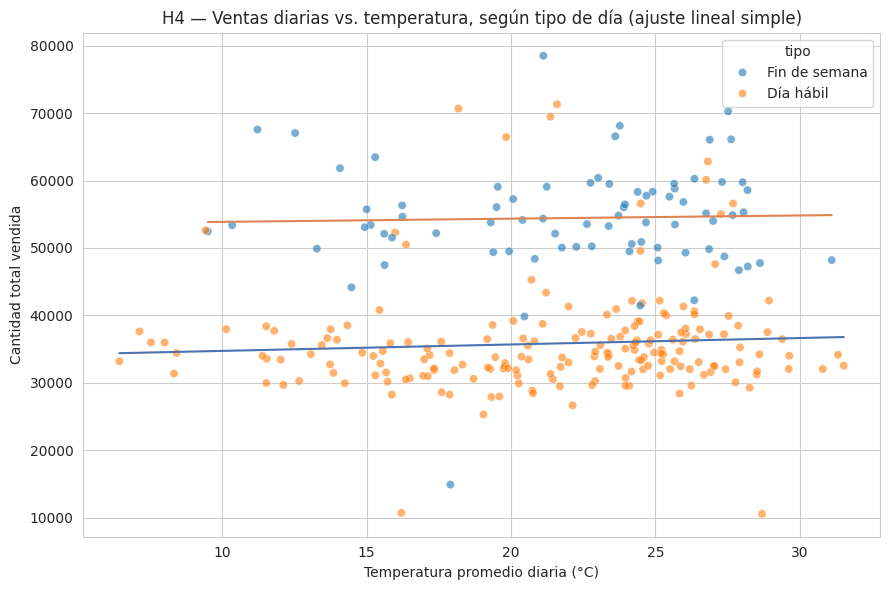

In [39]:
# --- 5.5 Gráfico de apoyo ---
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=agg_h4.assign(tipo=agg_h4['es_fin_de_semana'].map({0: 'Día hábil', 1: 'Fin de semana'})),
                x='temperatura_promedio', y='cantidad_total', hue='tipo', alpha=0.6, ax=ax)
for valor, color in [(0, '#4C72B0'), (1, '#DD8452')]:
    d = agg_h4[agg_h4['es_fin_de_semana'] == valor]
    pend, ord_ = np.polyfit(d['temperatura_promedio'], d['cantidad_total'], 1)
    xs = np.linspace(d['temperatura_promedio'].min(), d['temperatura_promedio'].max(), 50)
    ax.plot(xs, pend * xs + ord_, color=color)
ax.set_title('H4 — Ventas diarias vs. temperatura, según tipo de día (ajuste lineal simple)')
ax.set_xlabel('Temperatura promedio diaria (°C)')
ax.set_ylabel('Cantidad total vendida')
plt.tight_layout()
plt.show()

In [40]:
# --- 5.6 Conclusión -- H4 ---
p_h4 = modelo_h4_hc3.pvalues[term]
coef_h4 = modelo_h4.params[term]
signif_h4 = p_h4 < 0.05
hab, fin = pendientes_h4.loc['Día hábil'], pendientes_h4.loc['Fin de semana']
ic_h4 = np.asarray(modelo_h4_hc3.conf_int().loc[term])
coinciden = (modelo_h4.pvalues[term] < 0.05) == signif_h4

display(Markdown(f'''
### Conclusión -- H4

{"Se rechaza" if signif_h4 else "No se rechaza"} la hipótesis nula (p = {p_h4:.4f} con errores HC3; MCO clásico: p = {modelo_h4.pvalues[term]:.4f}{"" if coinciden else ", **discrepan**: tomar con cautela"}).
El coeficiente de interacción es **{coef_h4:.1f} unidades/°C** (IC95 [{ic_h4[0]:.1f}; {ic_h4[1]:.1f}]): por cada grado adicional, el fin de semana
{"suma" if coef_h4 > 0 else "resta"} {abs(coef_h4):.1f} unidades respecto de la pendiente de un día hábil.

Pendiente en día hábil: **{hab["unidades_por_°C"]:.1f}** unidades/°C (p = {hab["p_valor"]:.3f}). Pendiente en fin de semana: **{fin["unidades_por_°C"]:.1f}** unidades/°C (p = {fin["p_valor"]:.3f}).

**Robustez:** en logaritmos la interacción da p = {p_log:.4f}; a nivel local × día, p = {p_ld:.4f}.

**Supuestos:** Shapiro-Wilk p = {shapiro_h4[1]:.5f} {"(residuos no normales; con n=" + str(len(agg_h4)) + " se apoya en el TCL, como en H2)" if shapiro_h4[1] < 0.05 else ""}; Breusch-Pagan p = {bp_h4[1]:.4f} {"(heterocedasticidad: por eso la decisión se toma con HC3)" if bp_h4[1] < 0.05 else "(sin heterocedasticidad clara; HC3 se reporta igual por ser el caso límite en H2)"}.

**Potencia:** con 271 días (≈{int(agg_h4["es_fin_de_semana"].sum())} de fin de semana) un IC amplio indica que un efecto moderado podría no detectarse; no rechazar H0 no equivale a probar que no hay moderación.
**Limitación temporal:** igual que H2, solo enero-septiembre de 2021.
'''))


### Conclusión -- H4

No se rechaza la hipótesis nula (p = 0.9105 con errores HC3; MCO clásico: p = 0.8992).
El coeficiente de interacción es **25.3 unidades/°C** (IC95 [-415.6; 466.2]): por cada grado adicional, el fin de semana
suma 25.3 unidades respecto de la pendiente de un día hábil.

Pendiente en día hábil: **-136.8** unidades/°C (p = 0.216). Pendiente en fin de semana: **-111.5** unidades/°C (p = 0.628).

**Robustez:** en logaritmos la interacción da p = 0.8170; a nivel local × día, p = 0.1076.

**Supuestos:** Shapiro-Wilk p = 0.00000 (residuos no normales; con n=271 se apoya en el TCL, como en H2); Breusch-Pagan p = 0.0661 (sin heterocedasticidad clara; HC3 se reporta igual por ser el caso límite en H2).

**Potencia:** con 271 días (≈78 de fin de semana) un IC amplio indica que un efecto moderado podría no detectarse; no rechazar H0 no equivale a probar que no hay moderación.
**Limitación temporal:** igual que H2, solo enero-septiembre de 2021.


# 6. H5 — El efecto climático varía por local

**H0 (nula):** el efecto de la temperatura sobre las ventas es igual entre los locales; no existe interacción temperatura × local.

**H1 (alternativa):** el efecto de la temperatura sobre las ventas difiere entre los locales; existe interacción temperatura × local.

**Nivel de significancia:** α = 0.05

**Decisiones de diseño (y por qué):**
- **Unidad de análisis = cantidad total por fecha × local** (panel de ≈540 observaciones). La temperatura es una variable *diaria* y cada local tiene una única estación asignada, así que dentro de un (fecha, local) la temperatura es constante. Las ~9.4 millones de transacciones no son observaciones independientes respecto del clima: usarlas como unidad inflaría artificialmente el tamaño muestral.
- **Variable respuesta en nivel (`cantidad_total`, unidades/día)**, como propone la consigna del trabajo. Por eso cada pendiente se lee en **unidades por °C**. Como los dos locales difieren mucho en escala, en 6.6 se repite todo en **logaritmos** (allí la pendiente se lee como **% por °C**); ambas lecturas se mantienen separadas.
- **Temperatura centrada** (`temp_c = temperatura − media`): el coeficiente de `temp_c` es la pendiente del local de referencia, y los efectos de `local` y de calendario se leen a la temperatura media.
- **Controles de calendario con efecto propio por cada local** (fin de semana, feriado y mes × local). La fórmula inicial sugerida (`temp_c * C(local) + es_fin_de_semana + es_feriado + C(mes)`) impone que el calendario afecte *igual* a ambos locales. Esa restricción se **contrasta con los datos** en 6.2 (es una restricción sobre los controles, no sobre la pendiente de temperatura) y, si se rechaza, el modelo principal es el que no la impone. La fórmula inicial sigue reportada en la tabla de robustez (6.6) para que se vea cuánto depende el resultado de esta elección.
- **Errores estándar agrupados por fecha** (ver la celda siguiente).
- **`estacion_asignada` y `local`**: si cada local tiene una única estación y viceversa, ambas variables codifican lo mismo. Se usa `local` como factor y `estacion_asignada` solo para describir la correspondencia (6.1); incluir ambas sería redundante (colinealidad perfecta).


In [41]:
# --- 6.1 Estructura de los datos: columnas disponibles y correspondencia local -> estación meteorológica ---
cols_necesarias_h5 = ['fecha_vta', 'local', 'cantidad', 'temperatura', 'es_fin_de_semana', 'es_feriado', 'mes']
faltan_h5 = [c_ for c_ in cols_necesarias_h5 if c_ not in df_final.columns]
assert not faltan_h5, f"Faltan columnas en df_final: {faltan_h5}"
tiene_estacion_h5 = 'estacion_asignada' in df_final.columns
print(f"¿Existe 'estacion_asignada' en df_final? {tiene_estacion_h5}")

if tiene_estacion_h5:
    tabla_local_estacion = pd.crosstab(df_final['local'], df_final['estacion_asignada'])
    print("\nRegistros por local x estación asignada:")
    display(tabla_local_estacion)
    n_est_por_local = df_final.groupby('local', observed=True)['estacion_asignada'].nunique()
    n_loc_por_est = df_final.groupby('estacion_asignada', observed=True)['local'].nunique()
    correspondencia_fija_h5 = bool(n_est_por_local.max() == 1 and n_loc_por_est.max() == 1)
    print(f"Estaciones distintas por local: {n_est_por_local.to_dict()}")
    print(f"Locales distintos por estación: {n_loc_por_est.to_dict()}")
    print(f"-> Correspondencia 1 a 1 entre local y estación: {correspondencia_fija_h5}")
else:
    correspondencia_fija_h5 = False

# Panel fecha x local
agregados_h5 = dict(
    cantidad_total=('cantidad', 'sum'),
    temperatura=('temperatura', 'mean'),
    temp_min=('temperatura', 'min'),
    temp_max=('temperatura', 'max'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
    mes=('mes', 'first'),
    n_registros=('cantidad', 'size'),
)
if tiene_estacion_h5:
    agregados_h5['estacion_asignada'] = ('estacion_asignada', 'first')

panel_h5 = df_final.groupby(['fecha_vta', 'local'], observed=True).agg(**agregados_h5).reset_index()
assert float((panel_h5['temp_max'] - panel_h5['temp_min']).max()) == 0.0, "La temperatura no es constante dentro de (fecha, local)"
panel_h5 = panel_h5.drop(columns=['temp_min', 'temp_max'])

panel_h5['local'] = panel_h5['local'].astype(str)
for c_ in ['es_fin_de_semana', 'es_feriado', 'mes']:
    panel_h5[c_] = panel_h5[c_].astype(int)
panel_h5['temp_c'] = panel_h5['temperatura'] - panel_h5['temperatura'].mean()
panel_h5 = panel_h5.sort_values(['local', 'fecha_vta']).reset_index(drop=True)

locales_h5 = sorted(panel_h5['local'].unique())
local_ref_h5 = locales_h5[0]
print(f"\nPanel H5: {len(panel_h5)} observaciones fecha x local ({panel_h5['fecha_vta'].nunique()} fechas, {len(locales_h5)} locales: {locales_h5})")
print("La temperatura es constante dentro de cada (fecha, local): verificado.")

dias_por_local = panel_h5.groupby('local')['fecha_vta'].nunique()
todas_fechas_h5 = set(panel_h5['fecha_vta'])
for loc_ in locales_h5:
    faltantes_ = sorted(todas_fechas_h5 - set(panel_h5.loc[panel_h5['local'] == loc_, 'fecha_vta']))
    if faltantes_:
        print(f"{loc_}: sin registros en {len(faltantes_)} fecha(s): {[str(f_.date()) for f_ in faltantes_]} (el panel queda levemente desbalanceado)")

desc_h5 = panel_h5.groupby('local').agg(
    dias=('fecha_vta', 'nunique'),
    venta_diaria_media=('cantidad_total', 'mean'),
    venta_diaria_sd=('cantidad_total', 'std'),
    temp_media=('temperatura', 'mean'),
    temp_sd=('temperatura', 'std'),
    temp_min=('temperatura', 'min'),
    temp_max=('temperatura', 'max'),
)
if tiene_estacion_h5:
    desc_h5.insert(0, 'estacion_asignada', panel_h5.groupby('local')['estacion_asignada'].first())
display(desc_h5.round(2))

# ¿Cuánta variación climática "independiente" hay entre los dos locales?
temp_ancha_h5 = panel_h5.pivot(index='fecha_vta', columns='local', values='temperatura').dropna()
corr_temp_locales = float(temp_ancha_h5.corr().iloc[0, 1])
dif_temp_locales = temp_ancha_h5[locales_h5[1]] - temp_ancha_h5[locales_h5[0]]
print(f"\nCorrelación diaria entre las temperaturas de las dos estaciones: {corr_temp_locales:.3f}")
print(f"Diferencia de temperatura {locales_h5[1]} - {locales_h5[0]}: media {dif_temp_locales.mean():+.2f}°C, desvío {dif_temp_locales.std():.2f}°C")
print("-> Las dos series de temperatura se mueven casi juntas: la comparación entre locales se apoya en muy poca variación climática independiente.")


¿Existe 'estacion_asignada' en df_final? True



Registros por local x estación asignada:


estacion_asignada,"Asunción, Silvio Pettirossi, Capital de la Republica","Encarnación, Dpto. de Itapua"
local,,
Local X,6420811,0
Local Y,0,3026851


Estaciones distintas por local: {'Local X': 1, 'Local Y': 1}
Locales distintos por estación: {'Asunción, Silvio Pettirossi, Capital de la Republica': 1, 'Encarnación, Dpto. de  Itapua': 1}
-> Correspondencia 1 a 1 entre local y estación: True



Panel H5: 540 observaciones fecha x local (271 fechas, 2 locales: ['Local X', 'Local Y'])
La temperatura es constante dentro de cada (fecha, local): verificado.
Local X: sin registros en 2 fecha(s): ['2021-06-15', '2021-09-11'] (el panel queda levemente desbalanceado)


,estacion_asignada,dias,venta_diaria_media,venta_diaria_sd,temp_media,temp_sd,temp_min,temp_max
local,,,,,,,,
Local X,"Asunción, Silvio Pettirossi, Capital de la Rep...",269,28187.94,8457.72,22.13,5.47,6.4,32.9
Local Y,"Encarnación, Dpto. de Itapua",271,13194.28,3296.96,20.43,5.25,6.5,30.7



Correlación diaria entre las temperaturas de las dos estaciones: 0.962
Diferencia de temperatura Local Y - Local X: media -1.68°C, desvío 1.50°C
-> Las dos series de temperatura se mueven casi juntas: la comparación entre locales se apoya en muy poca variación climática independiente.


### ¿Por qué se agrupan los errores estándar por fecha?

Los modelos de OLS suponen que los errores de distintas observaciones son independientes. En el panel `fecha × local` eso es dudoso por dos motivos:

1. **Mismo día, mismo contexto.** Los dos locales de una misma fecha comparten calendario (día de la semana, feriado, clima regional, eventos, promociones de la cadena). Los *shocks* no observados de ese día afectan a ambos locales a la vez, así que sus errores están correlacionados (en 6.4 se mide esa correlación). Ignorarlo produce errores estándar incorrectos. La dirección del error depende del parámetro: para coeficientes que describen lo que es *común* a los dos locales, ignorar la correlación subestima el error (p-valores optimistas); para un contraste que *compara* a los dos locales el mismo día, como la interacción temperatura × local, el *shock* común se cancela en la diferencia y el error estándar clásico queda **sobrestimado**. El agrupamiento por fecha corrige ambos casos.
2. **Dependencia entre días.** Las ventas diarias de un local tienen inercia (un día "bueno" tiende a ser seguido por otro). En 6.4 se mide la autocorrelación residual.

El agrupamiento por `fecha` (≈271 *clusters*) deja libre la correlación **dentro** del día y trata los días como independientes entre sí. Es la misma lógica usada en H3 (donde las secciones y locales de un día compartían clima y calendario). Resuelve (1), pero **no** corrige del todo la autocorrelación entre días (2); por eso en 6.6 se verifica la conclusión también agrupando por semana.

Con `use_t=True` los intervalos y p-valores usan la distribución *t* con (nº de clusters − 1) grados de libertad, que es más prudente que la normal.


In [42]:
# --- 6.2 Modelo principal de H5: ¿la pendiente de temperatura depende del local? ---
import re

FORMULA_H5 = 'cantidad_total ~ C(local) * (temp_c + es_fin_de_semana + es_feriado + C(mes))'           # completo (H1)
FORMULA_H5_RESTR = 'cantidad_total ~ C(local) * (es_fin_de_semana + es_feriado + C(mes)) + temp_c'     # pendiente común (H0)
FORMULA_H5_COMUN = 'cantidad_total ~ temp_c * C(local) + es_fin_de_semana + es_feriado + C(mes)'      # calendario común (fórmula inicial)

def ajustar_cluster_t(formula, datos, col_cluster='fecha_vta'):
    '''OLS con errores estándar robustos agrupados (por defecto, por fecha) e inferencia con distribución t.'''
    grupos_ = pd.factorize(datos[col_cluster])[0]
    return smf.ols(formula, data=datos).fit(cov_type='cluster', cov_kwds={'groups': grupos_}, use_t=True)

def nombres_interaccion_h5(modelo):
    '''Coeficientes temp_c x local (patsy puede invertir el orden de los factores).'''
    return [n_ for n_ in modelo.params.index if ':' in str(n_) and 'temp_c' in str(n_) and 'local' in str(n_)]

modelo_h5 = ajustar_cluster_t(FORMULA_H5, panel_h5)            # inferencia principal (cluster por fecha)
modelo_h5_ols = smf.ols(FORMULA_H5, data=panel_h5).fit()       # mismo modelo con MCO clásico (diagnóstico y tamaño del efecto)
modelo_h5_restr_ols = smf.ols(FORMULA_H5_RESTR, data=panel_h5).fit()

terminos_int_h5 = nombres_interaccion_h5(modelo_h5)
print("Coeficiente(s) de interacción temperatura x local:", terminos_int_h5)
term_h5 = terminos_int_h5[0]          # con 2 locales hay una sola interacción: pendiente(local Y) - pendiente(local X)

# (a) Test principal: Wald conjunto robusto (con 2 locales es 1 solo término -> F = t²)
nombres_h5 = list(modelo_h5.params.index)
idx_int_h5 = [nombres_h5.index(n_) for n_ in terminos_int_h5]
R_h5 = np.zeros((len(idx_int_h5), len(nombres_h5)))
for k_, j_ in enumerate(idx_int_h5):
    R_h5[k_, j_] = 1
wald_h5 = modelo_h5.wald_test(R_h5, use_f=True, scalar=True)
f_h5, p_h5 = float(wald_h5.statistic), float(wald_h5.pvalue)
gl_num_h5, gl_den_h5 = len(idx_int_h5), float(wald_h5.df_denom)

coef_int_h5 = float(modelo_h5.params[term_h5])
ic_int_h5 = np.asarray(modelo_h5.conf_int().loc[term_h5], dtype=float)         # IC95% robusto (cluster, t)
ic_int_h5_clasico = np.asarray(modelo_h5_ols.conf_int().loc[term_h5], dtype=float)  # IC95% MCO clásico
f_cl_h5, p_cl_h5, _ = modelo_h5_ols.compare_f_test(modelo_h5_restr_ols)

# (b) Tamaño del efecto: R² parcial de la interacción y f² de Cohen
r2_parcial_h5 = (modelo_h5_restr_ols.ssr - modelo_h5_ols.ssr) / modelo_h5_restr_ols.ssr
f2_h5 = r2_parcial_h5 / (1 - r2_parcial_h5)
media_diaria_h5 = panel_h5['cantidad_total'].mean()
signif_h5 = p_h5 < 0.05

print(f"\nTest de interacción temperatura x local (Wald F robusto, agrupado por fecha): F({gl_num_h5}, {gl_den_h5:.0f}) = {f_h5:.3f}, p = {p_h5:.4f}")
print(f"Referencia, F clásico (supone independencia y varianza constante):       F = {f_cl_h5:.3f}, p = {p_cl_h5:.4f}")
print(f"Coeficiente de interacción ({term_h5}): {coef_int_h5:+.1f} unidades/°C")
print(f"   IC95% robusto (cluster por fecha, t): [{ic_int_h5[0]:.1f}; {ic_int_h5[1]:.1f}]   |   IC95% MCO clásico: [{ic_int_h5_clasico[0]:.1f}; {ic_int_h5_clasico[1]:.1f}]")
print(f"R² parcial de la interacción = {r2_parcial_h5:.5f} | f² = {f2_h5:.5f} -> {calificar_f2(f2_h5)}")
print(f"La diferencia de pendientes equivale a {coef_int_h5 / media_diaria_h5 * 100:+.2f}% de la venta diaria media del panel ({media_diaria_h5:,.0f} unidades) por °C")
print(f"Decisión (α = 0.05): {'Se rechaza H0' if signif_h5 else 'No se rechaza H0'}")

# (c) ¿Está justificado dar calendario propio a cada local? Test de las restricciones sobre los CONTROLES
ctrl_x_local_h5 = [i_ for i_, n_ in enumerate(nombres_h5) if ':' in str(n_) and 'temp_c' not in str(n_)]
R_ctrl_h5 = np.zeros((len(ctrl_x_local_h5), len(nombres_h5)))
for k_, j_ in enumerate(ctrl_x_local_h5):
    R_ctrl_h5[k_, j_] = 1
w_ctrl_h5 = modelo_h5.wald_test(R_ctrl_h5, use_f=True, scalar=True)
f_ctrl_h5, p_ctrl_h5 = float(w_ctrl_h5.statistic), float(w_ctrl_h5.pvalue)
print(f"\nTest de que fin de semana, feriado y mes afectan IGUAL a ambos locales (restricción de la fórmula inicial): "
      f"F({len(ctrl_x_local_h5)}, {w_ctrl_h5.df_denom:.0f}) = {f_ctrl_h5:.2f}, p = {p_ctrl_h5:.3g}")
print(f"-> {'Se rechaza: el calendario NO afecta igual a ambos locales, por lo que el modelo con calendario propio por local es el apropiado.' if p_ctrl_h5 < 0.05 else 'No se rechaza: el calendario común sería admisible.'}")


Coeficiente(s) de interacción temperatura x local: ['C(local)[T.Local Y]:temp_c']

Test de interacción temperatura x local (Wald F robusto, agrupado por fecha): F(1, 270) = 2.856, p = 0.0922
Referencia, F clásico (supone independencia y varianza constante):       F = 1.020, p = 0.3129
Coeficiente de interacción (C(local)[T.Local Y]:temp_c): +83.2 unidades/°C
   IC95% robusto (cluster por fecha, t): [-13.7; 180.1]   |   IC95% MCO clásico: [-78.6; 245.0]
R² parcial de la interacción = 0.00197 | f² = 0.00198 -> efecto insignificante
La diferencia de pendientes equivale a +0.40% de la venta diaria media del panel (20,663 unidades) por °C
Decisión (α = 0.05): No se rechaza H0

Test de que fin de semana, feriado y mes afectan IGUAL a ambos locales (restricción de la fórmula inicial): F(10, 270) = 96.97, p = 2.43e-83
-> Se rechaza: el calendario NO afecta igual a ambos locales, por lo que el modelo con calendario propio por local es el apropiado.


In [43]:
# --- 6.3 Efecto de +1°C sobre las ventas, por local (unidades/°C) ---
# Pendiente de cada local = combinación lineal de coeficientes del modelo principal:
#   local de referencia -> coef(temp_c); otro local -> coef(temp_c) + coef(interacción).
def pendientes_por_local(modelo, locales, local_ref):
    nombres_ = list(modelo.params.index)
    filas_ = []
    for loc_ in locales:
        L_ = np.zeros(len(nombres_))
        L_[nombres_.index('temp_c')] = 1
        if loc_ != local_ref:
            nom_ = [n_ for n_ in nombres_interaccion_h5(modelo) if f'[T.{loc_}]' in n_][0]
            L_[nombres_.index(nom_)] = 1
        tt_ = modelo.t_test(L_)
        lo_, hi_ = np.asarray(tt_.conf_int(), dtype=float).ravel()[:2]
        filas_.append({'local': loc_, 'coef': float(np.squeeze(tt_.effect)), 'IC95_inf': lo_, 'IC95_sup': hi_,
                       'p_valor': float(np.squeeze(tt_.pvalue))})
    tabla_ = pd.DataFrame(filas_)
    # Estos 2 tests individuales ("¿la pendiente de este local es 0?") son descriptivos y secundarios:
    # se muestra Holm solo por transparencia. El test principal de H5 es UNO solo y no requiere corrección.
    tabla_['p_holm'] = multipletests(tabla_['p_valor'], method='holm')[1]
    return tabla_

pend_h5 = pendientes_por_local(modelo_h5, locales_h5, local_ref_h5)
pend_h5['venta_diaria_media'] = pend_h5['local'].map(panel_h5.groupby('local')['cantidad_total'].mean())
pend_h5['efecto_%_de_la_venta_media_por_°C'] = pend_h5['coef'] / pend_h5['venta_diaria_media'] * 100   # conversión descriptiva
if tiene_estacion_h5:
    pend_h5.insert(1, 'estacion_asignada', pend_h5['local'].map(panel_h5.groupby('local')['estacion_asignada'].first()))
display(pend_h5.round(4))
print("Unidades: unidades vendidas por día por cada +1°C (modelo en nivel). La última columna solo reescala esa pendiente "
      "a % de la venta diaria media del local, para poder compararlos; no es un modelo en logaritmos (eso está en 6.6).")


,local,estacion_asignada,coef,IC95_inf,IC95_sup,p_valor,p_holm,venta_diaria_media,efecto_%_de_la_venta_media_por_°C
0,Local X,"Asunción, Silvio Pettirossi, Capital de la Rep...",-129.8313,-260.7672,1.1046,0.0520,0.1039,28187.9421,-0.4606
1,Local Y,"Encarnación, Dpto. de Itapua",-46.6349,-118.0228,24.7530,0.1995,0.1995,13194.2815,-0.3534


Unidades: unidades vendidas por día por cada +1°C (modelo en nivel). La última columna solo reescala esa pendiente a % de la venta diaria media del local, para poder compararlos; no es un modelo en logaritmos (eso está en 6.6).


1) Normalidad -- Shapiro-Wilk: W = 0.8434, p = 1.13e-22 -> residuos NO normales
2) Homocedasticidad -- Breusch-Pagan: LM = 79.78, p = 3.45e-08 -> HAY heterocedasticidad
   Desvío de los residuos por local: {'Local X': 4571.9, 'Local Y': 2590.4} | Levene entre locales: p = 1.12e-05
3) VIF (efectos principales, con dummies de mes): temp_c = 1.85; máximo = 2.38
   VIF sin mes (temp_c, local, temp_c x local, fin de semana, feriado): máximo = 1.98
4) Independencia -- Durbin-Watson por local: {'Local X': 1.7, 'Local Y': 1.65} (≈2 = sin autocorrelación) | autocorrelación lag-1: {'Local X': 0.15, 'Local Y': 0.18}
   Correlación entre los residuos de ambos locales el MISMO día: 0.833


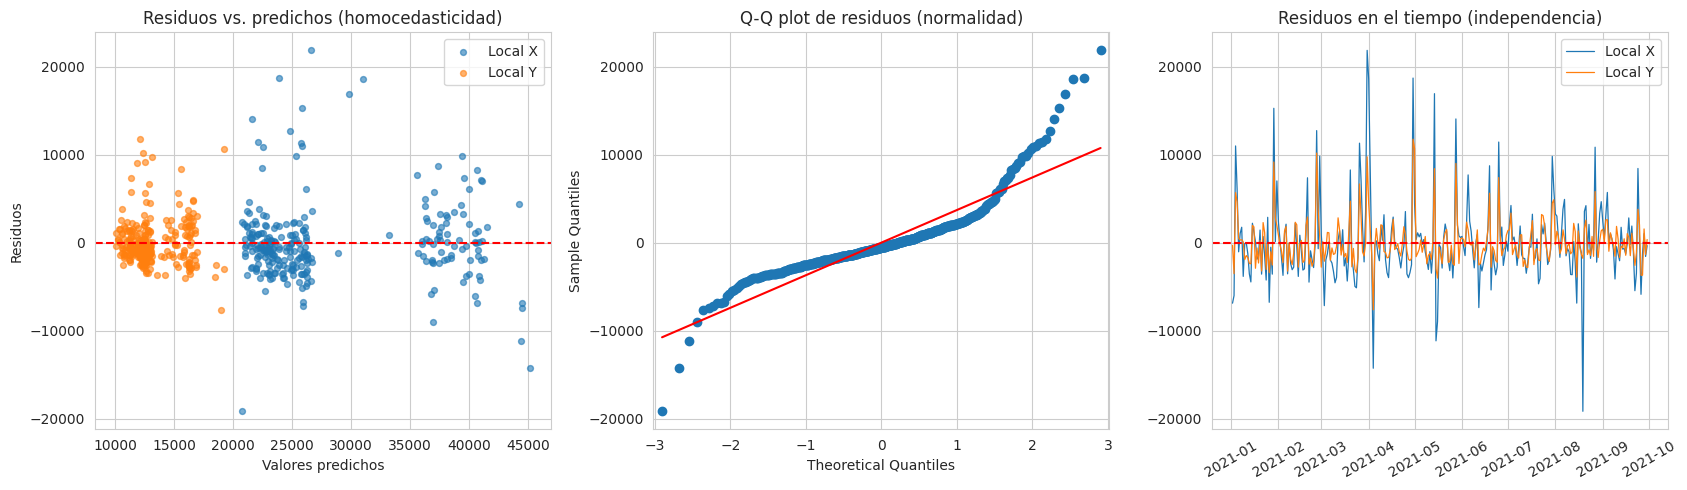


**Lectura de los supuestos (H5):**
- **Normalidad:** los residuos NO son normales (Shapiro p = 1.1e-22); con n = 540 y un solo contraste de 1 gl, el Teorema Central del Límite sostiene la inferencia aproximada, y el IC bootstrap (6.7) no depende de la normalidad.
- **Homocedasticidad:** hay heterocedasticidad (Breusch-Pagan p = 3.4e-08); el desvío residual difiere entre locales ({'Local X': 4572.0, 'Local Y': 2590.0}), lo esperable cuando un local vende el doble que otro. Por eso la decisión se toma con errores robustos, no con el F clásico.
- **Multicolinealidad:** el VIF de `temp_c` es 1.85 cuando se incluyen las dummies de mes (sin problema); sin el mes el VIF máximo es 1.98. No supera los umbrales habituales (5–10).
- **Independencia:** hay dependencia: los residuos de ambos locales del mismo día correlacionan 0.83 y la autocorrelación lag-1 es {'Local X': 0.15, 'Local Y': 0.18}; por eso se agrupan los errores por fecha y se verifica además con clusters semanales.


In [44]:
# --- 6.4 Supuestos del modelo de H5 ---
# Se examinan los residuos del modelo principal con MCO clásico (los diagnósticos clásicos se calculan sobre ese ajuste).
res_h5 = modelo_h5_ols.resid
panel_h5['resid_h5'] = res_h5.values

# 1) Normalidad
sh_h5 = stats.shapiro(res_h5)        # n < 5000: se usan todos los residuos
# 2) Homocedasticidad
bp_h5 = het_breuschpagan(res_h5, modelo_h5_ols.model.exog)
sd_res_local = panel_h5.groupby('local')['resid_h5'].std()
lev_h5 = levene(*[g_['resid_h5'].values for _, g_ in panel_h5.groupby('local')])
# 3) Multicolinealidad (VIF) -- con la temperatura centrada y calendario común (efectos principales)
mm_vif_h5 = smf.ols('cantidad_total ~ temp_c + C(local) + es_fin_de_semana + es_feriado + C(mes)', data=panel_h5).fit().model
vif_h5 = pd.DataFrame({'variable': mm_vif_h5.exog_names,
                       'VIF': [variance_inflation_factor(mm_vif_h5.exog, i_) for i_ in range(mm_vif_h5.exog.shape[1])]})
vif_h5 = vif_h5[vif_h5['variable'] != 'Intercept'].reset_index(drop=True)
vif_temp_h5 = float(vif_h5.loc[vif_h5['variable'] == 'temp_c', 'VIF'].iloc[0])
# VIF del bloque temperatura x local sin mes (la interacción se infla por construcción en un modelo con interacciones)
mm_vif_h5b = smf.ols('cantidad_total ~ temp_c * C(local) + es_fin_de_semana + es_feriado', data=panel_h5).fit().model
vif_h5b = pd.DataFrame({'variable': mm_vif_h5b.exog_names,
                        'VIF': [variance_inflation_factor(mm_vif_h5b.exog, i_) for i_ in range(mm_vif_h5b.exog.shape[1])]})
vif_h5b = vif_h5b[vif_h5b['variable'] != 'Intercept'].reset_index(drop=True)
# 4) Independencia
def autocorr_lag1(x):
    return float(np.corrcoef(x[1:], x[:-1])[0, 1])
dw_h5 = {l_: float(sm.stats.durbin_watson(g_.sort_values('fecha_vta')['resid_h5'].values)) for l_, g_ in panel_h5.groupby('local')}
ac1_h5 = {l_: autocorr_lag1(g_.sort_values('fecha_vta')['resid_h5'].values) for l_, g_ in panel_h5.groupby('local')}
res_ancho = panel_h5.pivot(index='fecha_vta', columns='local', values='resid_h5').dropna()
corr_resid_mismo_dia = float(res_ancho.corr().iloc[0, 1])
dw_min_h5 = min(dw_h5.values())

print(f"1) Normalidad -- Shapiro-Wilk: W = {sh_h5.statistic:.4f}, p = {sh_h5.pvalue:.3g} -> {'residuos NO normales' if sh_h5.pvalue < 0.05 else 'No se rechaza normalidad'}")
print(f"2) Homocedasticidad -- Breusch-Pagan: LM = {bp_h5[0]:.2f}, p = {bp_h5[1]:.3g} -> {'HAY heterocedasticidad' if bp_h5[1] < 0.05 else 'No se rechaza homocedasticidad'}")
print(f"   Desvío de los residuos por local: { {k_: round(v_, 1) for k_, v_ in sd_res_local.items()} } | Levene entre locales: p = {lev_h5.pvalue:.3g}")
print(f"3) VIF (efectos principales, con dummies de mes): temp_c = {vif_temp_h5:.2f}; máximo = {vif_h5['VIF'].max():.2f}")
print(f"   VIF sin mes (temp_c, local, temp_c x local, fin de semana, feriado): máximo = {vif_h5b['VIF'].max():.2f}")
print(f"4) Independencia -- Durbin-Watson por local: { {k_: round(v_, 2) for k_, v_ in dw_h5.items()} } (≈2 = sin autocorrelación) | autocorrelación lag-1: { {k_: round(v_, 2) for k_, v_ in ac1_h5.items()} }")
print(f"   Correlación entre los residuos de ambos locales el MISMO día: {corr_resid_mismo_dia:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for loc_, g_ in panel_h5.groupby('local'):
    axes[0].scatter(modelo_h5_ols.fittedvalues[g_.index], g_['resid_h5'], alpha=0.6, s=18, label=loc_)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Valores predichos'); axes[0].set_ylabel('Residuos'); axes[0].legend()
axes[0].set_title('Residuos vs. predichos (homocedasticidad)')
sm.qqplot(res_h5, line='s', ax=axes[1])
axes[1].set_title('Q-Q plot de residuos (normalidad)')
for loc_, g_ in panel_h5.groupby('local'):
    axes[2].plot(g_.sort_values('fecha_vta')['fecha_vta'], g_.sort_values('fecha_vta')['resid_h5'], lw=0.9, label=loc_)
axes[2].axhline(0, color='red', linestyle='--')
axes[2].set_title('Residuos en el tiempo (independencia)')
axes[2].tick_params(axis='x', rotation=30); axes[2].legend()
plt.tight_layout(); plt.show()

nota_norm = (f"los residuos NO son normales (Shapiro p = {sh_h5.pvalue:.2g}); con n = {len(panel_h5)} y un solo contraste de 1 gl, "
             "el Teorema Central del Límite sostiene la inferencia aproximada, y el IC bootstrap (6.7) no depende de la normalidad")
nota_het = (f"hay heterocedasticidad (Breusch-Pagan p = {bp_h5[1]:.2g}); el desvío residual difiere entre locales ({sd_res_local.round(0).to_dict()}), "
            "lo esperable cuando un local vende el doble que otro. Por eso la decisión se toma con errores robustos, no con el F clásico"
            ) if bp_h5[1] < 0.05 else f"no se rechaza homocedasticidad (p = {bp_h5[1]:.3f}); se usan igualmente errores robustos"
nota_ind = (f"hay dependencia: los residuos de ambos locales del mismo día correlacionan {corr_resid_mismo_dia:.2f} y la autocorrelación lag-1 es "
            f"{ {k_: round(v_, 2) for k_, v_ in ac1_h5.items()} }; por eso se agrupan los errores por fecha y se verifica además con clusters semanales")
display(Markdown(f'''
**Lectura de los supuestos (H5):**
- **Normalidad:** {nota_norm}.
- **Homocedasticidad:** {nota_het}.
- **Multicolinealidad:** el VIF de `temp_c` es {vif_temp_h5:.2f} cuando se incluyen las dummies de mes ({"es moderado: la temperatura es en buena medida estacional y el mes absorbe parte de su variación" if vif_temp_h5 > 2 else "sin problema"}); sin el mes el VIF máximo es {vif_h5b["VIF"].max():.2f}. {"No supera los umbrales habituales (5–10)." if max(vif_temp_h5, vif_h5b["VIF"].max()) < 5 else "Revisar."}
- **Independencia:** {nota_ind}.
'''))


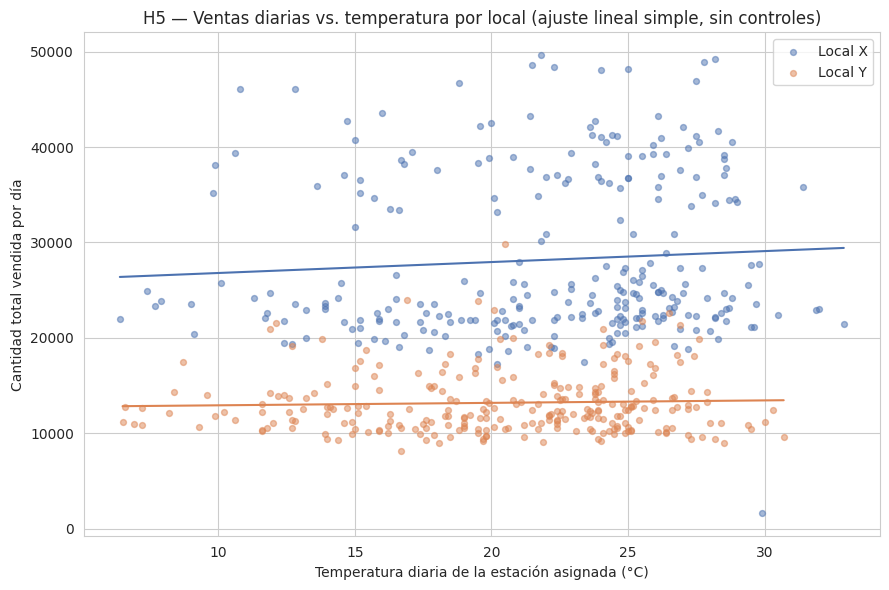

Gráfico descriptivo: no controla calendario ni mes; la inferencia sale del modelo de 6.2.


In [45]:
# --- 6.5 Gráfico: ventas diarias vs. temperatura, por local ---
fig, ax = plt.subplots(figsize=(9, 6))
paleta_h5 = {locales_h5[0]: '#4C72B0', locales_h5[1]: '#DD8452'}
for loc_, g_ in panel_h5.groupby('local'):
    ax.scatter(g_['temperatura'], g_['cantidad_total'], alpha=0.5, s=18, color=paleta_h5[loc_], label=loc_)
    pend_, ord_ = np.polyfit(g_['temperatura'], g_['cantidad_total'], 1)
    xs_ = np.linspace(g_['temperatura'].min(), g_['temperatura'].max(), 50)
    ax.plot(xs_, pend_ * xs_ + ord_, color=paleta_h5[loc_])
ax.set_xlabel('Temperatura diaria de la estación asignada (°C)'); ax.set_ylabel('Cantidad total vendida por día')
ax.set_title('H5 — Ventas diarias vs. temperatura por local (ajuste lineal simple, sin controles)')
ax.legend(); plt.tight_layout(); plt.show()
print("Gráfico descriptivo: no controla calendario ni mes; la inferencia sale del modelo de 6.2.")


In [46]:
# --- 6.6 Robustez: ¿la conclusión depende de cómo se especifica el modelo? ---
def resumen_int(modelo, nombre):
    nm_ = nombres_interaccion_h5(modelo)[0]
    ci_ = np.asarray(modelo.conf_int().loc[nm_], dtype=float)
    return {'especificación': nombre, 'interacción (unid./°C)': float(modelo.params[nm_]),
            'IC95_inf': ci_[0], 'IC95_sup': ci_[1], 'p_valor': float(modelo.pvalues[nm_])}

panel_h5['semana'] = panel_h5['fecha_vta'].dt.isocalendar().week.astype(int).values
stud_h5 = modelo_h5_ols.get_influence().resid_studentized_external
mask_ok_h5 = np.abs(stud_h5) <= 3
n_atipicos_h5 = int((~mask_ok_h5).sum())

filas_rob = [
    resumen_int(modelo_h5, 'PRINCIPAL: calendario propio por local, cluster por fecha (t)'),
    resumen_int(ajustar_cluster_t(FORMULA_H5_COMUN, panel_h5), 'Calendario común a ambos locales (fórmula inicial), cluster por fecha'),
    resumen_int(modelo_h5_ols, 'Principal con MCO clásico'),
    resumen_int(smf.ols(FORMULA_H5, data=panel_h5).fit(cov_type='HC3'), 'Principal con errores HC3'),
    resumen_int(ajustar_cluster_t(FORMULA_H5, panel_h5, col_cluster='semana'), f'Principal, cluster por semana ISO ({panel_h5["semana"].nunique()} clusters)'),
    resumen_int(ajustar_cluster_t(FORMULA_H5, panel_h5[np.asarray(mask_ok_h5)].reset_index(drop=True)),
                f'Principal sin {n_atipicos_h5} obs. atípicas (|resid. estudentizado| > 3)'),
    resumen_int(ajustar_cluster_t('cantidad_total ~ C(local) * (temp_c + es_fin_de_semana + es_feriado)', panel_h5), 'Principal sin control por mes'),
]
tabla_rob_h5 = pd.DataFrame(filas_rob)
print("A) Modelos en NIVEL -- la interacción se lee en unidades/°C (pendiente de {} menos pendiente de {}):".format(locales_h5[1], locales_h5[0]))
display(tabla_rob_h5.round(4))
n_rechazan_nivel = int((tabla_rob_h5['p_valor'] < 0.05).sum())
signos_nivel = np.sign(tabla_rob_h5['interacción (unid./°C)']).unique().tolist()

# B) Modelo en LOGARITMOS (misma estructura): la pendiente se lee como % por °C
assert (panel_h5['cantidad_total'] > 0).all(), "log requiere cantidad_total > 0"
panel_h5['log_cant'] = np.log(panel_h5['cantidad_total'])
FORMULA_H5_LOG = FORMULA_H5.replace('cantidad_total', 'log_cant')
modelo_h5_log = ajustar_cluster_t(FORMULA_H5_LOG, panel_h5)
nm_log = nombres_interaccion_h5(modelo_h5_log)[0]
p_h5_log = float(modelo_h5_log.pvalues[nm_log])
coef_int_log = float(modelo_h5_log.params[nm_log])
ic_int_log = np.asarray(modelo_h5_log.conf_int().loc[nm_log], dtype=float)
pend_log = pendientes_por_local(modelo_h5_log, locales_h5, local_ref_h5)
for c_ in ['coef', 'IC95_inf', 'IC95_sup']:
    pend_log['%_' + c_] = (np.exp(pend_log[c_]) - 1) * 100       # exp(b) - 1 = cambio relativo por °C
print("\nB) Modelo en LOGARITMOS -- la pendiente se lee como cambio PORCENTUAL de la venta diaria por +1°C: (exp(b) - 1) x 100")
display(pend_log[['local', 'p_valor', 'p_holm', '%_coef', '%_IC95_inf', '%_IC95_sup']].round(4))
print(f"Interacción en logaritmos: {coef_int_log:+.5f} log-puntos/°C (IC95% [{ic_int_log[0]:.5f}; {ic_int_log[1]:.5f}]), p = {p_h5_log:.4f}")
print(f"   (diferencia relativa entre las pendientes de {locales_h5[1]} y {locales_h5[0]}: {(np.exp(coef_int_log) - 1) * 100:+.2f} puntos porcentuales por °C; IC95% [{(np.exp(ic_int_log[0]) - 1) * 100:+.2f}; {(np.exp(ic_int_log[1]) - 1) * 100:+.2f}])")
print(f"\nResumen de robustez: {n_rechazan_nivel} de {len(tabla_rob_h5)} especificaciones en nivel rechazan H0 al 5%"
      f" (signos de la interacción: {signos_nivel}); en logaritmos p = {p_h5_log:.4f}.")


A) Modelos en NIVEL -- la interacción se lee en unidades/°C (pendiente de Local Y menos pendiente de Local X):


,especificación,interacción (unid./°C),IC95_inf,IC95_sup,p_valor
0,"PRINCIPAL: calendario propio por local, cluste...",83.1964,-13.7242,180.1170,0.0922
1,Calendario común a ambos locales (fórmula inic...,-118.6888,-249.7102,12.3326,0.0756
2,Principal con MCO clásico,83.1964,-78.6046,244.9974,0.3129
3,Principal con errores HC3,83.1964,-70.1204,236.5132,0.2875
4,"Principal, cluster por semana ISO (40 clusters)",83.1964,-20.5621,186.9549,0.1129
5,Principal sin 14 obs. atípicas (|resid. estude...,27.3355,-45.1371,99.8081,0.4584
6,Principal sin control por mes,-39.5490,-103.5094,24.4114,0.2245



B) Modelo en LOGARITMOS -- la pendiente se lee como cambio PORCENTUAL de la venta diaria por +1°C: (exp(b) - 1) x 100


,local,p_valor,p_holm,%_coef,%_IC95_inf,%_IC95_sup
0,Local X,0.1544,0.2597,-0.8254,-1.9522,0.3143
1,Local Y,0.1299,0.2597,-0.3856,-0.8831,0.1144


Interacción en logaritmos: +0.00442 log-puntos/°C (IC95% [-0.00599; 0.01484]), p = 0.4034
   (diferencia relativa entre las pendientes de Local Y y Local X: +0.44 puntos porcentuales por °C; IC95% [-0.60; +1.49])

Resumen de robustez: 0 de 7 especificaciones en nivel rechazan H0 al 5% (signos de la interacción: [1.0, -1.0]); en logaritmos p = 0.4034.


Método: bootstrap por bloques (cluster = fecha), 271 fechas remuestreadas con reemplazo en cada réplica
Réplicas: 2000 (válidas: 2000; descartadas por rango incompleto: 0) | semilla: 42 (np.random.default_rng)
Estimación puntual de la interacción: +83.2 unidades/°C | media bootstrap: +82.1


,IC95_inf,IC95_sup,error_estandar,ancho,contiene_0
"Clásico (MCO, t)",-78.60,245.00,82.36,323.60,True
Robusto: cluster por fecha (t),-13.72,180.12,49.23,193.84,True
Bootstrap por fecha (percentil),-3.70,183.12,48.19,186.82,True


Bootstrap -- IC95% de la pendiente de cada local (unid./°C): {'Local X': [-269.7, -7.6], 'Local Y': [-121.5, 23.3]}
Proporción de réplicas con la interacción de signo opuesto al estimado puntual: 0.031


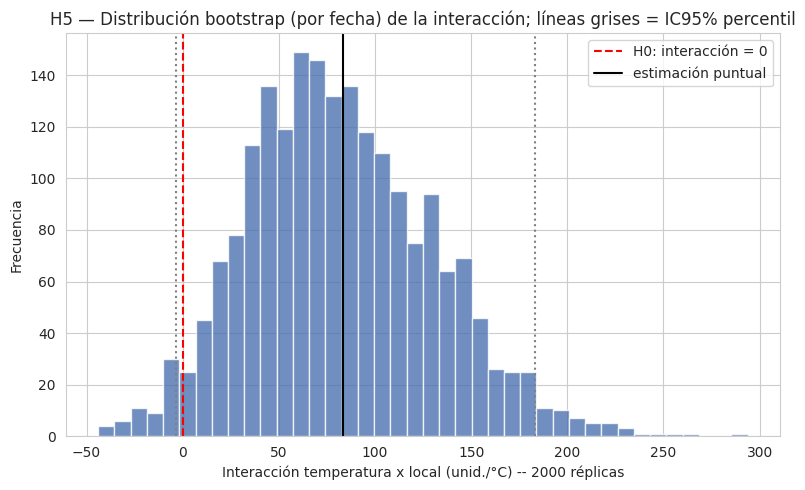

In [47]:
# --- 6.7 Bootstrap por clusters de fecha: IC 95% de la interacción, comparado con el IC clásico ---
# Se remuestrean FECHAS con reemplazo (no filas): cada fecha remuestreada trae consigo sus observaciones de ambos locales,
# de modo que se conserva la dependencia dentro del día. En cada réplica se reestima el modelo principal por MCO y se
# guarda la interacción (diferencia de pendientes) y la pendiente de cada local.
SEMILLA_BOOT = 42
N_BOOT = 2000

y_h5 = modelo_h5_ols.model.endog
X_h5 = modelo_h5_ols.model.exog
cols_h5 = list(modelo_h5_ols.model.exog_names)
j_int_h5 = cols_h5.index(term_h5)
j_temp_h5 = cols_h5.index('temp_c')

cod_fecha_h5 = pd.factorize(panel_h5['fecha_vta'])[0]
G_h5 = int(cod_fecha_h5.max()) + 1
filas_por_fecha_h5 = [np.flatnonzero(cod_fecha_h5 == k_) for k_ in range(G_h5)]

rng_h5 = np.random.default_rng(SEMILLA_BOOT)
boot_h5 = np.full((N_BOOT, 3), np.nan)       # columnas: interacción, pendiente local ref., pendiente otro local
n_deficientes_h5 = 0
for b_ in range(N_BOOT):
    sel_ = rng_h5.integers(0, G_h5, size=G_h5)
    filas_b = np.concatenate([filas_por_fecha_h5[k_] for k_ in sel_])
    Xb_, yb_ = X_h5[filas_b], y_h5[filas_b]
    if np.linalg.matrix_rank(Xb_) < X_h5.shape[1]:          # réplica con diseño de rango incompleto: se descarta
        n_deficientes_h5 += 1
        continue
    beta_ = np.linalg.lstsq(Xb_, yb_, rcond=None)[0]
    boot_h5[b_] = [beta_[j_int_h5], beta_[j_temp_h5], beta_[j_temp_h5] + beta_[j_int_h5]]
boot_ok_h5 = boot_h5[~np.isnan(boot_h5[:, 0])]

ic_boot_int = np.percentile(boot_ok_h5[:, 0], [2.5, 97.5])
se_boot_int = float(boot_ok_h5[:, 0].std(ddof=1))
se_cluster_int = float(modelo_h5.bse[term_h5])
se_clasico_int = float(modelo_h5_ols.bse[term_h5])
ic_boot_pend = {locales_h5[0]: np.percentile(boot_ok_h5[:, 1], [2.5, 97.5]), locales_h5[1]: np.percentile(boot_ok_h5[:, 2], [2.5, 97.5])}
prop_signo_opuesto = float(np.mean(np.sign(boot_ok_h5[:, 0]) != np.sign(coef_int_h5)))

comp_ic_h5 = pd.DataFrame({
    'IC95_inf': [ic_int_h5_clasico[0], ic_int_h5[0], ic_boot_int[0]],
    'IC95_sup': [ic_int_h5_clasico[1], ic_int_h5[1], ic_boot_int[1]],
    'error_estandar': [se_clasico_int, se_cluster_int, se_boot_int],
}, index=['Clásico (MCO, t)', 'Robusto: cluster por fecha (t)', 'Bootstrap por fecha (percentil)'])
comp_ic_h5['ancho'] = comp_ic_h5['IC95_sup'] - comp_ic_h5['IC95_inf']
comp_ic_h5['contiene_0'] = (comp_ic_h5['IC95_inf'] <= 0) & (comp_ic_h5['IC95_sup'] >= 0)

print(f"Método: bootstrap por bloques (cluster = fecha), {G_h5} fechas remuestreadas con reemplazo en cada réplica")
print(f"Réplicas: {N_BOOT} (válidas: {len(boot_ok_h5)}; descartadas por rango incompleto: {n_deficientes_h5}) | semilla: {SEMILLA_BOOT} (np.random.default_rng)")
print(f"Estimación puntual de la interacción: {coef_int_h5:+.1f} unidades/°C | media bootstrap: {boot_ok_h5[:, 0].mean():+.1f}")
display(comp_ic_h5.round(2))
print(f"Bootstrap -- IC95% de la pendiente de cada local (unid./°C): { {k_: np.round(v_, 1).tolist() for k_, v_ in ic_boot_pend.items()} }")
print(f"Proporción de réplicas con la interacción de signo opuesto al estimado puntual: {prop_signo_opuesto:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(boot_ok_h5[:, 0], bins=40, color='#4C72B0', alpha=0.8)
ax.axvline(0, color='red', linestyle='--', label='H0: interacción = 0')
ax.axvline(coef_int_h5, color='black', label='estimación puntual')
for v_ in ic_boot_int:
    ax.axvline(v_, color='gray', linestyle=':')
ax.set_xlabel(f'Interacción temperatura x local (unid./°C) -- {N_BOOT} réplicas'); ax.set_ylabel('Frecuencia')
ax.set_title('H5 — Distribución bootstrap (por fecha) de la interacción; líneas grises = IC95% percentil')
ax.legend(); plt.tight_layout(); plt.show()


In [48]:
# --- 6.8 Conclusión -- H5 ---
dif_signo_h5 = 'menos negativa' if coef_int_h5 > 0 else 'más negativa'
pl_ref = pend_h5.set_index('local').loc[local_ref_h5]
pl_otro = pend_h5.set_index('local').loc[locales_h5[1]]
n_pend_sig_h5 = int((pend_h5['p_valor'] < 0.05).sum())
hay_discrepancia_h5 = bool(np.sign(tabla_rob_h5['interacción (unid./°C)'].iloc[0]) != np.sign(tabla_rob_h5['interacción (unid./°C)'].iloc[1]))
ratio_ancho = comp_ic_h5.loc['Bootstrap por fecha (percentil)', 'ancho'] / comp_ic_h5.loc['Robusto: cluster por fecha (t)', 'ancho']
ic_incluye_0_h5 = bool(ic_int_h5[0] <= 0 <= ic_int_h5[1])

if signif_h5:
    texto_interp_h5 = (f"los datos indican que el efecto de la temperatura sobre las ventas difiere entre {local_ref_h5} y {locales_h5[1]}; "
                       "aun así, la magnitud debe juzgarse con el tamaño del efecto y es una asociación, no una causa.")
else:
    texto_interp_h5 = (f"con los datos disponibles no hay evidencia suficiente de que el efecto de la temperatura difiera entre {local_ref_h5} y {locales_h5[1]}. "
                       "Esto no demuestra que los efectos sean iguales: " +
                       ("el IC incluye el 0 pero también diferencias de ambos signos." if ic_incluye_0_h5 else "revisar el IC."))

display(Markdown(f'''
### Conclusión -- H5

**Decisión:** {"Se rechaza H0" if signif_h5 else "No se rechaza H0"} (F({gl_num_h5}, {gl_den_h5:.0f}) = {f_h5:.2f}, p = {p_h5:.4f}; errores agrupados por fecha; α = 0.05).

**Diferencia de pendientes ({locales_h5[1]} − {local_ref_h5}):** {coef_int_h5:+.1f} unidades/°C, IC95% [{ic_int_h5[0]:.1f}; {ic_int_h5[1]:.1f}]. En el modelo principal, la pendiente de {locales_h5[1]} es {dif_signo_h5} que la de {local_ref_h5}; {"el IC incluye el 0, así que los datos no permiten distinguir esa diferencia de cero" if ic_incluye_0_h5 else "el IC excluye el 0"}.

**Pendientes por local (unidades por día por +1°C):** {local_ref_h5}: {pl_ref["coef"]:+.1f} (IC95% [{pl_ref["IC95_inf"]:.1f}; {pl_ref["IC95_sup"]:.1f}], p = {pl_ref["p_valor"]:.3f}); {locales_h5[1]}: {pl_otro["coef"]:+.1f} (IC95% [{pl_otro["IC95_inf"]:.1f}; {pl_otro["IC95_sup"]:.1f}], p = {pl_otro["p_valor"]:.3f}). {n_pend_sig_h5} de 2 pendientes son distinguibles de cero al 5%.

**Tamaño del efecto:** R² parcial de la interacción = {r2_parcial_h5:.4f} (f² = {f2_h5:.4f}: {calificar_f2(f2_h5)}): la interacción explica el {r2_parcial_h5*100:.2f}% de la variabilidad que el modelo sin interacción deja sin explicar. La diferencia de pendientes equivale a {abs(coef_int_h5) / media_diaria_h5 * 100:.2f}% de la venta diaria media del panel por °C.

**Bootstrap por fecha ({N_BOOT} réplicas, semilla {SEMILLA_BOOT}):** IC95% [{ic_boot_int[0]:.1f}; {ic_boot_int[1]:.1f}] vs. IC clásico [{ic_int_h5_clasico[0]:.1f}; {ic_int_h5_clasico[1]:.1f}] y robusto [{ic_int_h5[0]:.1f}; {ic_int_h5[1]:.1f}]. {"Los tres incluyen el 0" if comp_ic_h5["contiene_0"].all() else ("Los tres excluyen el 0" if (~comp_ic_h5["contiene_0"]).all() else "Los intervalos no coinciden respecto del 0")}; el ancho del bootstrap es {ratio_ancho:.2f} veces el del IC robusto ({"consistentes entre sí" if 0.8 <= ratio_ancho <= 1.25 else "diferencia apreciable"}). {"El IC clásico es más ancho (error estándar " + f"{se_clasico_int:.1f}" + " vs. " + f"{se_cluster_int:.1f}" + " con clusters) porque no aprovecha que ambos locales comparten los shocks de cada día, que se cancelan al comparar sus pendientes." if se_clasico_int > se_cluster_int else ""}

**Robustez (6.6):** {n_rechazan_nivel} de {len(tabla_rob_h5)} especificaciones en nivel rechazan H0 al 5%; en logaritmos p = {p_h5_log:.3f}. {"**Atención:** el SIGNO de la interacción cambia entre la especificación principal y la de calendario común (filas 1 y 2 de la tabla 6.6): la estimación es imprecisa y no debe leerse como que un local sea más sensible que el otro." if hay_discrepancia_h5 else "El signo de la interacción coincide entre la especificación principal y la de calendario común."}

**Interpretación:** {texto_interp_h5} Ambos locales se asocian a estaciones cuya temperatura diaria correlaciona {corr_temp_locales:.2f}, por lo que casi no hay variación climática independiente entre locales; además local y estación están perfectamente asociados ({"correspondencia 1 a 1 verificada en 6.1" if correspondencia_fija_h5 else "ver 6.1"}), de modo que no se puede separar el "efecto del local" del de su estación. Es una asociación estadística, no una relación causal.

**Comparaciones múltiples:** el contraste principal es uno solo (con 2 locales hay una única interacción), por lo que no corresponde ninguna corrección; los 2 tests por local de 6.3 son descriptivos (se muestra Holm por transparencia).
'''))



### Conclusión -- H5

**Decisión:** No se rechaza H0 (F(1, 270) = 2.86, p = 0.0922; errores agrupados por fecha; α = 0.05).

**Diferencia de pendientes (Local Y − Local X):** +83.2 unidades/°C, IC95% [-13.7; 180.1]. En el modelo principal, la pendiente de Local Y es menos negativa que la de Local X; el IC incluye el 0, así que los datos no permiten distinguir esa diferencia de cero.

**Pendientes por local (unidades por día por +1°C):** Local X: -129.8 (IC95% [-260.8; 1.1], p = 0.052); Local Y: -46.6 (IC95% [-118.0; 24.8], p = 0.199). 0 de 2 pendientes son distinguibles de cero al 5%.

**Tamaño del efecto:** R² parcial de la interacción = 0.0020 (f² = 0.0020: efecto insignificante): la interacción explica el 0.20% de la variabilidad que el modelo sin interacción deja sin explicar. La diferencia de pendientes equivale a 0.40% de la venta diaria media del panel por °C.

**Bootstrap por fecha (2000 réplicas, semilla 42):** IC95% [-3.7; 183.1] vs. IC clásico [-78.6; 245.0] y robusto [-13.7; 180.1]. Los tres incluyen el 0; el ancho del bootstrap es 0.96 veces el del IC robusto (consistentes entre sí). El IC clásico es más ancho (error estándar 82.4 vs. 49.2 con clusters) porque no aprovecha que ambos locales comparten los shocks de cada día, que se cancelan al comparar sus pendientes.

**Robustez (6.6):** 0 de 7 especificaciones en nivel rechazan H0 al 5%; en logaritmos p = 0.403. **Atención:** el SIGNO de la interacción cambia entre la especificación principal y la de calendario común (filas 1 y 2 de la tabla 6.6): la estimación es imprecisa y no debe leerse como que un local sea más sensible que el otro.

**Interpretación:** con los datos disponibles no hay evidencia suficiente de que el efecto de la temperatura difiera entre Local X y Local Y. Esto no demuestra que los efectos sean iguales: el IC incluye el 0 pero también diferencias de ambos signos. Ambos locales se asocian a estaciones cuya temperatura diaria correlaciona 0.96, por lo que casi no hay variación climática independiente entre locales; además local y estación están perfectamente asociados (correspondencia 1 a 1 verificada en 6.1), de modo que no se puede separar el "efecto del local" del de su estación. Es una asociación estadística, no una relación causal.

**Comparaciones múltiples:** el contraste principal es uno solo (con 2 locales hay una única interacción), por lo que no corresponde ninguna corrección; los 2 tests por local de 6.3 son descriptivos (se muestra Holm por transparencia).


# 7. Variable de confusión

Una **variable de confusión** es una variable que (i) influye en la exposición (aquí, la temperatura) y (ii) influye también en el resultado (las ventas). Si no se la considera, parte de la asociación temperatura–ventas es en realidad el efecto de esa tercera variable. Es distinta de una simple **variable de control**: una variable que solo afecta al resultado (y no está relacionada con la exposición) no confunde, aunque conviene incluirla porque reduce el ruido y mejora la precisión.

**Candidata principal: el mes (estacionalidad).** La temperatura depende del mes (verano más cálido que invierno) y las ventas también dependen de él, por razones ajenas al clima (calendario escolar, fechas comerciales, cobro de salarios, eventos). Entonces, sin controlar por mes, el coeficiente de temperatura mezcla el efecto del clima con la estacionalidad comercial. En el notebook esto se ve en tres lugares: H2 y H5 (`C(mes)` como control) y H3 (columna `efecto_%_sin_control_mes`).

**Fin de semana y feriado**, en cambio, afectan fuertemente las ventas, pero **no deberían depender de la temperatura**: son variables de control (precisión), no de confusión. La celda siguiente lo verifica con los datos.

**Contrapartida:** controlar por mes hace que el efecto de la temperatura se identifique solo con la variación *dentro de cada mes* (día a día), no con la estacionalidad. Si el clima actuara también a través de la estación (por ejemplo, hábitos de compra de verano), ese canal queda absorbido por el mes. Controlar por una variable que está en el camino causal puede quitar parte del efecto de interés, por eso se reportan ambas versiones.


In [49]:
# --- 7.1 Evidencia sobre la variable de confusión ---
# (1) ¿Cuánto de la variabilidad de la temperatura diaria es "mes"?  (serie diaria 'agg' de H2)
r2_temp_mes = smf.ols('temperatura_promedio ~ C(mes)', data=agg).fit().rsquared
# (2) ¿Cambia el coeficiente de temperatura (H2) al controlar o no por mes?
m_h2_sin_mes = smf.ols('cantidad_total ~ temperatura_promedio + es_fin_de_semana + es_feriado', data=agg).fit()
coef_h2_sin_mes, p_h2_sin_mes = float(m_h2_sin_mes.params['temperatura_promedio']), float(m_h2_sin_mes.pvalues['temperatura_promedio'])
# (3) H3: ¿cuántas secciones cambian de signo al sacar el mes?
n_cambian_signo_h3 = int((np.sign(tabla_h3['efecto_%_por_°C']) != np.sign(tabla_h3['efecto_%_sin_control_mes'])).sum())
# (4) H5: interacción con y sin control por mes
fila_sin_mes = tabla_rob_h5[tabla_rob_h5['especificación'] == 'Principal sin control por mes'].iloc[0]
# (5) Fin de semana / feriado vs. temperatura: ¿están relacionados con la exposición?
corr_temp_finde = float(agg['temperatura_promedio'].corr(agg['es_fin_de_semana']))
corr_temp_feriado = float(agg['temperatura_promedio'].corr(agg['es_feriado']))

print(f"(1) La variable 'mes' explica el {r2_temp_mes*100:.1f}% de la variación de la temperatura diaria (R² de temperatura ~ mes): fuerte relación mes -> temperatura.")
print(f"(2) H2 -- coeficiente de temperatura CON control por mes: {coef_temp:+.1f} (p = {p_valor_temp:.3f}) | SIN control por mes: {coef_h2_sin_mes:+.1f} (p = {p_h2_sin_mes:.3f})")
print(f"(3) H3 -- {n_cambian_signo_h3} de {len(tabla_h3)} secciones cambian de signo al quitar el control por mes.")
print(f"(4) H5 -- interacción con control por mes: {coef_int_h5:+.1f} (p = {p_h5:.3f}) | sin control por mes: {fila_sin_mes['interacción (unid./°C)']:+.1f} (p = {fila_sin_mes['p_valor']:.3f})")
print(f"(5) Correlación temperatura–fin de semana = {corr_temp_finde:+.3f}; temperatura–feriado = {corr_temp_feriado:+.3f} (cercanas a 0: no confunden, solo controlan).")


(1) La variable 'mes' explica el 44.2% de la variación de la temperatura diaria (R² de temperatura ~ mes): fuerte relación mes -> temperatura.
(2) H2 -- coeficiente de temperatura CON control por mes: -131.0 (p = 0.254) | SIN control por mes: +84.2 (p = 0.346)
(3) H3 -- 4 de 9 secciones cambian de signo al quitar el control por mes.
(4) H5 -- interacción con control por mes: +83.2 (p = 0.092) | sin control por mes: -39.5 (p = 0.225)
(5) Correlación temperatura–fin de semana = +0.066; temperatura–feriado = +0.005 (cercanas a 0: no confunden, solo controlan).


**Lectura:** la estacionalidad (mes) está fuertemente ligada a la temperatura y, a la vez, mueve las ventas por motivos no climáticos; es la variable de confusión plausible en este estudio, y los resultados de H2, H3 y H5 cambian de magnitud (y en algunos casos de signo) según se la controle o no. Fin de semana y feriado tienen un efecto grande sobre las ventas pero una relación casi nula con la temperatura: son controles que mejoran la precisión, no confusores. Con una sola ventana de 9 meses no se puede separar con certeza el efecto del clima del efecto de la estacionalidad: esa es la principal razón para leer los resultados como asociaciones.


# 8. Comparaciones múltiples: cuándo se corrige y cuándo no

La corrección es necesaria cuando se realizan **varios contrastes sobre la misma pregunta** y se declara significativo cualquiera que supere α, porque la probabilidad de al menos un falso positivo crece con el número de contrastes.

| Contraste | ¿Se corrige? | Cómo / por qué |
|---|---|---|
| H1 — 3 comparaciones por pares entre grupos climáticos | Sí | Tukey HSD controla el error global de las 3 comparaciones |
| H2 — un coeficiente (temperatura) | No | Un único contraste preespecificado |
| H3 — 9 pendientes por sección | **Sí, Holm** | 9 contrastes sobre la misma pregunta; la interpretación usa `p_holm` |
| H3 — subsecciones de Bebidas (exploratorio) | Sí, Holm | Análisis exploratorio con varias subsecciones |
| H3 — test conjunto de interacción | No | Una sola prueba conjunta (Wald F), no 9 pruebas separadas |
| H4 — un coeficiente (interacción) | No | Un único contraste |
| H5 — interacción temperatura × local | **No** | Con 2 locales hay una única interacción: un solo contraste, no hay familia que corregir |
| H5 — pendiente de cada local (2 tests) | Holm, solo informativo | Tests descriptivos secundarios; el contraste principal no depende de ellos |

La celda siguiente muestra qué pasaría si, además, se corrigiera por tener **5 hipótesis** (Bonferroni, α = 0.05/5 = 0.01) usando el contraste principal de cada una. No es la regla del trabajo (cada hipótesis responde una pregunta distinta, con su propio α), pero ayuda a ver qué conclusiones son frágiles.


In [50]:
# --- 8.1 Sensibilidad: ¿qué hipótesis sobreviven a una corrección por 5 hipótesis (Bonferroni)? ---
p_principales = {'H1 (grupo climático)': p_clima, 'H2 (temperatura)': p_valor_temp, 'H3 (temp x sección)': p_h3,
                 'H4 (temp x fin de semana)': float(modelo_h4_hc3.pvalues[term]), 'H5 (temp x local)': p_h5}
bonf = pd.DataFrame({'p_valor': pd.Series(p_principales)})
bonf['p_bonferroni (x5)'] = np.minimum(bonf['p_valor'] * len(bonf), 1.0)
bonf['significativa_sin_corregir'] = bonf['p_valor'] < 0.05
bonf['significativa_con_Bonferroni'] = bonf['p_bonferroni (x5)'] < 0.05
display(bonf)
print(f"Nota: H1 se evalúa aquí con su p-valor del ANOVA clásico; con errores agrupados por fecha su p-valor es {p_h1_cl:.3g}"
      f" ({'sigue siendo significativa' if p_h1_cl < 0.05 else 'deja de ser significativa'}).")


,p_valor,p_bonferroni (x5),significativa_sin_corregir,significativa_con_Bonferroni
H1 (grupo climático),2.742788e-13,1.371394e-12,True,True
H2 (temperatura),2.535938e-01,1.000000e+00,False,False
H3 (temp x sección),3.173594e-49,1.586797e-48,True,True
H4 (temp x fin de semana),9.105378e-01,1.000000e+00,False,False
H5 (temp x local),9.218152e-02,4.609076e-01,False,False


Nota: H1 se evalúa aquí con su p-valor del ANOVA clásico; con errores agrupados por fecha su p-valor es 0.176 (deja de ser significativa).


# 9. Tabla resumen de las hipótesis H1–H5

La tabla se construye con las variables calculadas en las secciones anteriores (no se escribe ningún valor a mano): si cambian los datos o la semilla, la tabla se actualiza al volver a ejecutar el notebook.


In [51]:
# --- 9.1 Tabla resumen H1-H5 (generada desde las variables del notebook) ---
def fmt_p(p):
    return f"{p:.2e}" if p < 0.001 else f"{p:.4f}"

def decision(p, alfa=0.05):
    return 'Se rechaza H0' if p < alfa else 'No se rechaza H0'

df_gl_clima = int(tabla_anova_h1.loc['C(grupo_climatico)', 'df'])
df_gl_res = int(tabla_anova_h1.loc['Residual', 'df'])
f_clima = float(tabla_anova_h1.loc['C(grupo_climatico)', 'F'])
vif_h2_max = float(vif_data.loc[vif_data['variable'] != 'const', 'VIF'].max())

filas_resumen = [
    {'Hipótesis': 'H1: ventas de la sección más sensible (' + seccion_objetivo + ') difieren por grupo climático',
     'Prueba': 'ANOVA de 2 factores (clima × local) + Tukey HSD',
     'Supuestos': f"Levene p = {fmt_p(levene_p)} (varianzas NO homogéneas); Shapiro (muestra) p = {fmt_p(shapiro_h1.pvalue)} (NO normal); "
                  f"con errores agrupados por fecha p = {fmt_p(p_h1_cl)}",
     'Estadístico': f"F({df_gl_clima}, {df_gl_res}) = {f_clima:.2f}",
     'p-valor': f"{fmt_p(p_clima)} (con errores agrupados por fecha: {fmt_p(p_h1_cl)})",
     'IC 95%': f"Caluroso−Frío: {dif_caluroso_frio:+.3f} [{ic_tukey_h1[0]:.3f}; {ic_tukey_h1[1]:.3f}] unid./registro (Tukey)",
     'Tamaño del efecto': f"eta² = {eta2_clima:.4f} ({calificar_eta2(eta2_clima)})",
     'Decisión': decision(p_clima) + ('' if p_h1_cl < 0.05 else f" (ANOVA clásico); NO robusta: con errores agrupados por fecha, {decision(p_h1_cl)}")},
    {'Hipótesis': 'H2: la temperatura se asocia a las ventas totales diarias (controlando calendario)',
     'Prueba': 'Regresión lineal múltiple (OLS), t del coeficiente de temperatura',
     'Supuestos': f"Shapiro p = {fmt_p(shapiro_p)} (NO normal); Breusch-Pagan p = {fmt_p(bp_p)}; VIF máx. = {vif_h2_max:.2f}; HC3 p = {fmt_p(p_h2_hc3)}",
     'Estadístico': f"t({gl_h2}) = {t_h2:.2f}",
     'p-valor': fmt_p(p_valor_temp),
     'IC 95%': f"{coef_temp:+.1f} [{ic_h2[0]:.1f}; {ic_h2[1]:.1f}] unid./°C",
     'Tamaño del efecto': f"R² parcial = {r2_parcial_h2:.4f} (f² = {f2_h2:.4f}: {calificar_f2(f2_h2)})",
     'Decisión': decision(p_valor_temp)},
    {'Hipótesis': 'H3: el efecto de la temperatura difiere entre secciones',
     'Prueba': 'Wald F robusto (cluster por fecha) de la interacción temp × sección sobre log(cantidad); pendientes con Holm',
     'Supuestos': f"Shapiro p = {fmt_p(sh_h3.pvalue)}; Breusch-Pagan p = {fmt_p(bp_h3[1])}; VIF temp_c = {vif_temp_h3:.2f}; errores agrupados por fecha (dependencia)",
     'Estadístico': f"F({len(idx_int)}, {wald_h3.df_denom:.0f}) = {f_h3:.2f}",
     'p-valor': fmt_p(p_h3),
     'IC 95%': f"Prueba conjunta (sin IC único). Pendientes por sección: {tabla_h3['efecto_%_por_°C'].min():+.2f}% a {tabla_h3['efecto_%_por_°C'].max():+.2f}% por °C (IC en 4.3)",
     'Tamaño del efecto': f"R² parcial = {r2_parcial_h3:.4f} (f² = {r2_parcial_h3/(1-r2_parcial_h3):.4f}: {calificar_f2(r2_parcial_h3/(1-r2_parcial_h3))})",
     'Decisión': decision(p_h3)},
    {'Hipótesis': 'H4: el fin de semana modera el efecto de la temperatura',
     'Prueba': 'Regresión OLS con interacción temp_c × fin de semana, errores HC3',
     'Supuestos': f"Shapiro p = {fmt_p(shapiro_h4[1])} (NO normal); Breusch-Pagan p = {fmt_p(bp_h4[1])}; VIF máx. = {float(vif_h4.loc[vif_h4['variable'] != 'const', 'VIF'].max()):.2f} (temp. centrada); HC3",
     'Estadístico': f"t({gl_h4}) = {t_h4:.2f}",
     'p-valor': fmt_p(float(modelo_h4_hc3.pvalues[term])),
     'IC 95%': f"{modelo_h4.params[term]:+.1f} [{ic_h4_hc3[0]:.1f}; {ic_h4_hc3[1]:.1f}] unid./°C (HC3)",
     'Tamaño del efecto': f"R² parcial = {r2_parcial_h4:.5f} (f² = {f2_h4:.5f}: {calificar_f2(f2_h4)})",
     'Decisión': decision(float(modelo_h4_hc3.pvalues[term]))},
    {'Hipótesis': 'H5: el efecto de la temperatura varía por local',
     'Prueba': 'Wald F robusto (cluster por fecha) de temp × local, nivel; IC también por bootstrap por fecha',
     'Supuestos': f"Shapiro p = {fmt_p(sh_h5.pvalue)} (NO normal); Breusch-Pagan p = {fmt_p(bp_h5[1])}; VIF temp_c = {vif_temp_h5:.2f}; "
                  f"correl. residual mismo día = {corr_resid_mismo_dia:.2f}",
     'Estadístico': f"F({gl_num_h5}, {gl_den_h5:.0f}) = {f_h5:.2f}",
     'p-valor': fmt_p(p_h5),
     'IC 95%': f"{coef_int_h5:+.1f} [{ic_int_h5[0]:.1f}; {ic_int_h5[1]:.1f}] unid./°C (robusto); bootstrap [{ic_boot_int[0]:.1f}; {ic_boot_int[1]:.1f}]",
     'Tamaño del efecto': f"R² parcial = {r2_parcial_h5:.4f} (f² = {f2_h5:.4f}: {calificar_f2(f2_h5)})",
     'Decisión': decision(p_h5)},
]
tabla_resumen = pd.DataFrame(filas_resumen)
with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    display(tabla_resumen)


,Hipótesis,Prueba,Supuestos,Estadístico,p-valor,IC 95%,Tamaño del efecto,Decisión
0,H1: ventas de la sección más sensible (Bebidas) difieren por grupo climático,ANOVA de 2 factores (clima × local) + Tukey HSD,Levene p = 4.02e-07 (varianzas NO homogéneas); Shapiro (muestra) p = 1.45e-89 (NO normal); con errores agrupados por fecha p = 0.1762,"F(2, 416335) = 28.93",2.74e-13 (con errores agrupados por fecha: 0.1762),Caluroso−Frío: +0.077 [0.047; 0.108] unid./registro (Tukey),eta² = 0.0001 (efecto insignificante),"Se rechaza H0 (ANOVA clásico); NO robusta: con errores agrupados por fecha, No se rechaza H0"
1,H2: la temperatura se asocia a las ventas totales diarias (controlando calendario),"Regresión lineal múltiple (OLS), t del coeficiente de temperatura",Shapiro p = 2.42e-14 (NO normal); Breusch-Pagan p = 0.0516; VIF máx. = 1.02; HC3 p = 0.2412,t(259) = -1.14,0.2536,-131.0 [-356.6; 94.5] unid./°C,R² parcial = 0.0050 (f² = 0.0051: efecto insignificante),No se rechaza H0
2,H3: el efecto de la temperatura difiere entre secciones,Wald F robusto (cluster por fecha) de la interacción temp × sección sobre log(cantidad); pendientes con Holm,Shapiro p = 1.24e-49; Breusch-Pagan p = 2.62e-272; VIF temp_c = 1.85; errores agrupados por fecha (dependencia),"F(8, 270) = 50.26",3.17e-49,Prueba conjunta (sin IC único). Pendientes por sección: -2.17% a +1.31% por °C (IC en 4.3),R² parcial = 0.0417 (f² = 0.0435: efecto pequeño),Se rechaza H0
3,H4: el fin de semana modera el efecto de la temperatura,"Regresión OLS con interacción temp_c × fin de semana, errores HC3",Shapiro p = 2.44e-14 (NO normal); Breusch-Pagan p = 0.0661; VIF máx. = 1.36 (temp. centrada); HC3,t(258) = 0.11,0.9105,+25.3 [-415.6; 466.2] unid./°C (HC3),R² parcial = 0.00006 (f² = 0.00006: efecto insignificante),No se rechaza H0
4,H5: el efecto de la temperatura varía por local,"Wald F robusto (cluster por fecha) de temp × local, nivel; IC también por bootstrap por fecha",Shapiro p = 1.13e-22 (NO normal); Breusch-Pagan p = 3.45e-08; VIF temp_c = 1.85; correl. residual mismo día = 0.83,"F(1, 270) = 2.86",0.0922,+83.2 [-13.7; 180.1] unid./°C (robusto); bootstrap [-3.7; 183.1],R² parcial = 0.0020 (f² = 0.0020: efecto insignificante),No se rechaza H0


# 10. Conclusión general de la Fase 2


In [52]:
# --- 10.1 Conclusión general (los números se leen de las variables calculadas) ---
n_h3_pos = int(((tabla_h3['efecto_%_por_°C'] > 0) & tabla_h3['signif_holm']).sum())
n_h3_neg = int(((tabla_h3['efecto_%_por_°C'] < 0) & tabla_h3['signif_holm']).sum())
secs_neg = ', '.join(tabla_h3.loc[(tabla_h3['efecto_%_por_°C'] < 0) & tabla_h3['signif_holm'], 'desc_secciones'])
p_h4_hc3 = float(modelo_h4_hc3.pvalues[term])
rango_h3 = (tabla_h3['efecto_%_por_°C'].min(), tabla_h3['efecto_%_por_°C'].max())

display(Markdown(f'''
## Qué hipótesis se sostienen y cuáles no

- **H2 — {"se rechaza H0" if p_valor_temp < 0.05 else "no se rechaza H0"}** (p = {p_valor_temp:.3f}). Sobre la serie diaria de {len(agg)} días no hay evidencia de que la temperatura se asocie a las ventas totales una vez controlado el calendario. El IC95% es [{ic_h2[0]:.0f}; {ic_h2[1]:.0f}] unid./°C ({"incluye el 0" if ic_h2[0] <= 0 <= ic_h2[1] else "excluye el 0"}); el R² parcial de la temperatura es {r2_parcial_h2:.4f}. Lo que domina las ventas totales es el calendario (fin de semana y feriados).
- **H1 — {"se rechaza H0 (ANOVA clásico)" if p_clima < 0.05 else "no se rechaza H0"}** para el efecto del grupo climático en "{seccion_objetivo}" (p = {p_clima:.2g}), con eta² = {eta2_clima:.4f} ({calificar_eta2(eta2_clima)}): la diferencia es mínima ({dif_caluroso_frio:+.3f} unidades por registro entre días calurosos y fríos). {"Además, la significancia no es robusta: las filas de un mismo día comparten clima y, con errores agrupados por fecha, p = " + f"{p_h1_cl:.2f}" + " y no se rechaza H0." if p_h1_cl >= 0.05 else "La conclusión se mantiene con errores agrupados por fecha (p = " + f"{p_h1_cl:.2g}" + ")."} {"No hay evidencia de que el patrón difiera entre locales" if p_interaccion_h1 >= 0.05 else "El patrón difiere entre locales"} (interacción clima × local: p = {p_interaccion_h1:.2f}).
- **H3 — {"se rechaza H0" if p_h3 < 0.05 else "no se rechaza H0"}** (F = {f_h3:.1f}, p = {p_h3:.2g}): el efecto de la temperatura no es el mismo en todas las secciones. La magnitud es modesta (R² parcial = {r2_parcial_h3:.3f}; efectos entre {rango_h3[0]:+.1f}% y {rango_h3[1]:+.1f}% por °C). Tras Holm, {n_h3_neg + n_h3_pos} secciones tienen efecto significativo ({n_h3_pos} positivas, {n_h3_neg} negativas: {secs_neg}); la evidencia de sustitución entre categorías es débil.
- **H4 — {"se rechaza H0" if p_h4_hc3 < 0.05 else "no se rechaza H0"}** (p = {p_h4_hc3:.2f}): {"no hay evidencia de que el fin de semana modifique el efecto de la temperatura" if p_h4_hc3 >= 0.05 else "el fin de semana modifica el efecto de la temperatura"}; el IC95% de la interacción es [{ic_h4_hc3[0]:.0f}; {ic_h4_hc3[1]:.0f}] unid./°C (±{(ic_h4_hc3[1]-ic_h4_hc3[0])/2/media_diaria_h4*100:.1f}% de la venta diaria media).
- **H5 — {"se rechaza H0" if p_h5 < 0.05 else "no se rechaza H0"}** (F({gl_num_h5}, {gl_den_h5:.0f}) = {f_h5:.2f}, p = {p_h5:.3f}): {"no hay evidencia suficiente de que el efecto de la temperatura difiera entre los locales" if p_h5 >= 0.05 else "el efecto de la temperatura difiere entre los locales"}. El IC95% de la diferencia de pendientes es [{ic_int_h5[0]:.0f}; {ic_int_h5[1]:.0f}] unid./°C (bootstrap por fecha [{ic_boot_int[0]:.0f}; {ic_boot_int[1]:.0f}]); {"incluye el 0" if ic_incluye_0_h5 else "excluye el 0"}{" y el signo de la estimación cambia según cómo se especifique el calendario (6.6), por lo que la estimación es imprecisa" if hay_discrepancia_h5 else ""}. R² parcial = {r2_parcial_h5:.4f}.

## Significancia estadística vs. relevancia práctica

Con cientos de miles de transacciones (H1) o miles de celdas (H3) los p-valores pueden ser diminutos aun para efectos pequeños: en H1, p = {p_clima:.1g} con eta² = {eta2_clima:.4f}{" (y ni siquiera resiste el agrupamiento por fecha)" if p_h1_cl >= 0.05 else ""}. Por eso las conclusiones se apoyan en el tamaño del efecto y en los intervalos de confianza, no solo en el p-valor. En conjunto, los efectos del clima detectados son pequeños (≈ {rango_h3[0]:+.1f}% a {rango_h3[1]:+.1f}% por °C por sección) frente al peso del calendario, y no respaldan fuertemente la hipótesis central del proyecto de que el clima explica una porción relevante de la variación de las ventas.

## Limitaciones de la inferencia

- Solo **{df_final["fecha_vta"].nunique()} días**, únicamente **enero–septiembre de 2021**: no se observa un ciclo estacional completo (faltan octubre–diciembre y otros años); el rango de temperaturas es acotado.
- Solo **dos locales** y **dos estaciones meteorológicas** asociadas (correspondencia 1 a 1), con temperaturas diarias casi idénticas (correlación {corr_temp_locales:.2f}): muy poca variación climática independiente. Local y estación no se pueden separar.
- **Dependencia temporal:** las observaciones de un mismo día comparten clima y calendario y hay autocorrelación entre días; se mitigó con errores agrupados por fecha (verificado por semana) y con bootstrap por fechas, pero con 271 días la precisión es limitada.
- El control por **mes** hace que el efecto se identifique con la variación día a día dentro de cada mes, no con la estacionalidad; los resultados cambian de magnitud (y a veces de signo) sin ese control (sección 7).
- Los resultados son **asociaciones, no causalidad**: variables no observadas (promociones, eventos, precios, clima percibido) pueden afectar a la vez ventas y temperatura.
- **Muestras grandes** producen p-valores muy pequeños incluso para efectos prácticos pequeños (H1); y con pocas observaciones (H4, H5) un resultado no significativo no prueba ausencia de efecto (potencia limitada).
- H1 se contrasta a nivel transacción (la cantidad es casi siempre 1) y con una submuestra estratificada por rendimiento; su significancia {"resiste" if p_h1_cl < 0.05 else "NO resiste"} el agrupamiento por fecha (2.8b y 2.11). Los análisis de H3 y H5, a nivel diario y con errores agrupados, son más defendibles.
- En {int((dias_por_local < dias_por_local.max()).sum())} local(es) faltan fechas de venta ({", ".join(f"{l_}: {dias_por_local.max() - n_}" for l_, n_ in dias_por_local.items() if n_ < dias_por_local.max())} día(s)); en esas fechas el total diario de H2 y H4 incluye solo a los demás locales.

## Variables que deberían pasar a la Fase 3

- **`temperatura`** (centrada) como variable climática principal, a nivel `fecha × local`.
- **`mes`** (estacionalidad) y **`es_fin_de_semana`**, **`es_feriado`** como controles obligatorios; `dia_semana` como alternativa más fina al fin de semana.
- **`local`** (con su calendario propio: el efecto del calendario difiere entre locales, sección 6.2) y **`desc_secciones`** / **`desc_sub_secciones`** como dimensión de segmentación (H3 mostró heterogeneidad por sección).
- Evaluar rezagos de la temperatura y la **cantidad agregada por fecha × local × sección** como variable objetivo (idealmente en logaritmos).
- Si se consigue una ventana temporal más larga y/o más locales con estaciones distintas, repetir H2–H5: es la mejora que más aumentaría la capacidad de detectar un efecto climático.
'''))



## Qué hipótesis se sostienen y cuáles no

- **H2 — no se rechaza H0** (p = 0.254). Sobre la serie diaria de 271 días no hay evidencia de que la temperatura se asocie a las ventas totales una vez controlado el calendario. El IC95% es [-357; 94] unid./°C (incluye el 0); el R² parcial de la temperatura es 0.0050. Lo que domina las ventas totales es el calendario (fin de semana y feriados).
- **H1 — se rechaza H0 (ANOVA clásico)** para el efecto del grupo climático en "Bebidas" (p = 2.7e-13), con eta² = 0.0001 (efecto insignificante): la diferencia es mínima (+0.077 unidades por registro entre días calurosos y fríos). Además, la significancia no es robusta: las filas de un mismo día comparten clima y, con errores agrupados por fecha, p = 0.18 y no se rechaza H0. No hay evidencia de que el patrón difiera entre locales (interacción clima × local: p = 0.18).
- **H3 — se rechaza H0** (F = 50.3, p = 3.2e-49): el efecto de la temperatura no es el mismo en todas las secciones. La magnitud es modesta (R² parcial = 0.042; efectos entre -2.2% y +1.3% por °C). Tras Holm, 3 secciones tienen efecto significativo (0 positivas, 3 negativas: Produccion, Almacen, Tienda); la evidencia de sustitución entre categorías es débil.
- **H4 — no se rechaza H0** (p = 0.91): no hay evidencia de que el fin de semana modifique el efecto de la temperatura; el IC95% de la interacción es [-416; 466] unid./°C (±1.1% de la venta diaria media).
- **H5 — no se rechaza H0** (F(1, 270) = 2.86, p = 0.092): no hay evidencia suficiente de que el efecto de la temperatura difiera entre los locales. El IC95% de la diferencia de pendientes es [-14; 180] unid./°C (bootstrap por fecha [-4; 183]); incluye el 0 y el signo de la estimación cambia según cómo se especifique el calendario (6.6), por lo que la estimación es imprecisa. R² parcial = 0.0020.

## Significancia estadística vs. relevancia práctica

Con cientos de miles de transacciones (H1) o miles de celdas (H3) los p-valores pueden ser diminutos aun para efectos pequeños: en H1, p = 3e-13 con eta² = 0.0001 (y ni siquiera resiste el agrupamiento por fecha). Por eso las conclusiones se apoyan en el tamaño del efecto y en los intervalos de confianza, no solo en el p-valor. En conjunto, los efectos del clima detectados son pequeños (≈ -2.2% a +1.3% por °C por sección) frente al peso del calendario, y no respaldan fuertemente la hipótesis central del proyecto de que el clima explica una porción relevante de la variación de las ventas.

## Limitaciones de la inferencia

- Solo **271 días**, únicamente **enero–septiembre de 2021**: no se observa un ciclo estacional completo (faltan octubre–diciembre y otros años); el rango de temperaturas es acotado.
- Solo **dos locales** y **dos estaciones meteorológicas** asociadas (correspondencia 1 a 1), con temperaturas diarias casi idénticas (correlación 0.96): muy poca variación climática independiente. Local y estación no se pueden separar.
- **Dependencia temporal:** las observaciones de un mismo día comparten clima y calendario y hay autocorrelación entre días; se mitigó con errores agrupados por fecha (verificado por semana) y con bootstrap por fechas, pero con 271 días la precisión es limitada.
- El control por **mes** hace que el efecto se identifique con la variación día a día dentro de cada mes, no con la estacionalidad; los resultados cambian de magnitud (y a veces de signo) sin ese control (sección 7).
- Los resultados son **asociaciones, no causalidad**: variables no observadas (promociones, eventos, precios, clima percibido) pueden afectar a la vez ventas y temperatura.
- **Muestras grandes** producen p-valores muy pequeños incluso para efectos prácticos pequeños (H1); y con pocas observaciones (H4, H5) un resultado no significativo no prueba ausencia de efecto (potencia limitada).
- H1 se contrasta a nivel transacción (la cantidad es casi siempre 1) y con una submuestra estratificada por rendimiento; su significancia NO resiste el agrupamiento por fecha (2.8b y 2.11). Los análisis de H3 y H5, a nivel diario y con errores agrupados, son más defendibles.
- En 1 local(es) faltan fechas de venta (Local X: 2 día(s)); en esas fechas el total diario de H2 y H4 incluye solo a los demás locales.

## Variables que deberían pasar a la Fase 3

- **`temperatura`** (centrada) como variable climática principal, a nivel `fecha × local`.
- **`mes`** (estacionalidad) y **`es_fin_de_semana`**, **`es_feriado`** como controles obligatorios; `dia_semana` como alternativa más fina al fin de semana.
- **`local`** (con su calendario propio: el efecto del calendario difiere entre locales, sección 6.2) y **`desc_secciones`** / **`desc_sub_secciones`** como dimensión de segmentación (H3 mostró heterogeneidad por sección).
- Evaluar rezagos de la temperatura y la **cantidad agregada por fecha × local × sección** como variable objetivo (idealmente en logaritmos).
- Si se consigue una ventana temporal más larga y/o más locales con estaciones distintas, repetir H2–H5: es la mejora que más aumentaría la capacidad de detectar un efecto climático.


# 11. Auditoría de los requisitos de la Fase 2

| # | Requisito | Dónde se cumple |
|---|---|---|
| 1 | Mínimo 4 contrastes | H1, H2, H3, H4 y H5 (5 contrastes principales) |
| 2 | Al menos 3 familias de pruebas | ANOVA de 2 factores + Tukey (H1); regresión lineal con t/HC3 (H2, H4); pruebas Wald F con errores agrupados (H3, H5); remuestreo bootstrap por clusters (H5) |
| 3 | H0 y H1 de cada contraste | Celdas Markdown al inicio de cada sección |
| 4 | α = 0.05 | Declarado en cada sección |
| 5 | Justificación de la prueba | Celdas "Decisiones de diseño" / "Método" de cada sección |
| 6 | Verificación de supuestos | H1: 2.4 y 2.8b; H2: 1.4; H3: 4.2b; H4: 5.3; H5: 6.4 |
| 7–9 | Estadístico, p-valor, IC | Tabla resumen (sección 9); H3 reporta IC por sección (4.3) porque su prueba principal es conjunta |
| 10 | Tamaño del efecto en cada prueba | H1: eta²; H2: R² parcial (1.3b); H3: R² parcial (4.2); H4: R² parcial (5.2b); H5: R² parcial y f² (6.2) |
| 11 | Corrección por comparaciones múltiples | Tukey (H1), Holm (H3); sección 8 explica cuándo no corresponde (H2, H4, H5) |
| 12 | Interpretación en lenguaje natural | Celdas "Conclusión" de cada sección y sección 10 |
| 13 | Significancia estadística vs. relevancia práctica | Conclusión de H1 y sección 10 |
| 14 | Variable de confusión | Sección 7 |
| 15 | IC bootstrap vs. IC clásico | 6.7 (bootstrap por fecha para la interacción de H5) |
| 16 | Conclusión general | Sección 10 |
| 17 | Limitaciones | Sección 10 |
| 18 | Variables para la Fase 3 | Sección 10 |

**Pendientes / matices honestos:** (i) la prueba de H3 es conjunta, por lo que no tiene un único IC; (ii) H1 usa registros de transacción con una submuestra por rendimiento: se añadió una verificación con errores agrupados por fecha, pero es el análisis menos robusto; (iii) la estimación de H5 no es estable ante la especificación del calendario (sección 6.6); (iv) el documento PDF de la Fase 2 sigue diciendo "H5 pendiente" y debe actualizarse con los resultados de la sección 6.
